# 31. Does the pretrained calibration predictor already know observability?

This notebook is derived from **the latest notebook 30**. It retains the same three-sensor KAIST split, scientific three-sensor observability cache, Student-t prior sampling, physical context augmentation, and paired correction loss. The only architectural change is an **additional shared observability output head**.

**Stage 1:** inspect cached scientific observability and its relationship to the original correction errors.

**Stage 2 (recommended):** freeze every parameter of pretrained `002.10`; extract its per-calibration `[B, 3, 128]` features from the **unaugmented** windows; train a lightweight shared `128 → 128 → 7` observability head; compare against a per-DOF training-mean baseline on unseen validation/test sequences.

**Stage 3 (optional):** fine-tune the original correction model with the same paired correction loss and an auxiliary observability head, comparing against correction-only fine-tuning from the exact same checkpoint on the same sampled priors.

**Important:** observability scores are **outputs/targets, not inputs**. The Transformer keeps its original 8-dimensional tokens. Cached labels are computed from nominal, unaugmented windows, so the auxiliary loss is evaluated on those same raw windows, not on altered calibration hypotheses. At inference, the new head requires no FG computation or score cache.


## 1. Imports and repository root


In [1]:
from pathlib import Path
import sys
import inspect
import time

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
from tqdm.auto import tqdm

ROOT = Path.cwd()
for candidate in (ROOT, *ROOT.parents):
    if (candidate / "src" / "obscalib").exists():
        ROOT = candidate
        break
else:
    raise FileNotFoundError("Could not locate the nn-obs-calib repository root containing src/obscalib.")

if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

from kaist_dataset.dataset import KAISTCalibrationDataset, KAISTRigCalibration, build_kaist_sequence_specs, make_kaist_dataloader
from obscalib.augmentations.config import AugmentationConfig, CalibrationEventConfig, FrameRandomizationConfig, NoiseAugmentationConfig, PerturbationMagnitudeConfig, PriorPerturbationConfig, SamplingRateAugmentationConfig, TrueCalibrationAugmentationConfig
from obscalib.augmentations.pipeline import AugmentationPipeline
from obscalib.augmentations import PerturbationDistribution
from obscalib.augmentations.prior_perturbation import CalibrationPriorPerturber, apply_prior_perturbation
from obscalib.calibration.state import CalibrationState
from obscalib.calibration.update import CalibrationUpdater
from obscalib.config import CalibrationPoolerConfig, MLPConfig, PooledCalibrationHeadConfig, PooledCalibrationModelConfig, TransformerConfig, WindowingConfig
from obscalib.data.collation import collate_windows
from obscalib.data.device import window_batch_to
from obscalib.data.structures import WindowBatch
from obscalib.geometry.lie import se3_log
from obscalib.geometry.processing import GeometryProcessor
from obscalib.observability.estimators import ObservabilityMatrixEstimator
from obscalib.observability.layout import CalibrationParameterLayout
from obscalib.observability.mappings import dimensionless_soft_projector_observability
from obscalib.observability.numerics import ObservabilityNumericsConfig
from obscalib.observability.structures import ObservabilityResult
from obscalib.models.pooled_calibration_model import PooledCalibrationModel
from obscalib.pipeline.window_step import WindowStep
from obscalib.tokenization.tokenizer import Tokenizer
from obscalib.training.checkpoint import load_training_checkpoint, save_training_checkpoint
from obscalib.training.metrics_logger import MetricsLogger
import gc

print("Repository root:", ROOT)
print("PyTorch:", torch.__version__)


Repository root: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib
PyTorch: 2.7.1+cu126


## 2. Configuration: original 8D calibration model, cached three-sensor observability targets

In [2]:
RUN_NAME = "kaist_pooled_calibration_paired_002.15_observability_output"

# Specify the exact previous successful checkpoint; this is a weights-only initialization.
# Change SOURCE_RUN_NAME to "kaist_pooled_calibration_paired_002.9_student" if that is your actual saved run directory.
SOURCE_RUN_NAME = "kaist_pooled_calibration_paired_002.10_fine_coarse"
RESUME_CHECKPOINT = ROOT / "runs" / SOURCE_RUN_NAME / "best.pt"
# RESUME_CHECKPOINT = ROOT / "runs" / RUN_NAME / "best.pt"

RANDOM_SEED = 12345
TRAIN_PAIR_SEED = 23456
VALIDATION_PAIR_SEED = 34567
TEST_PAIR_SEED = 45678
VISUALIZATION_PAIR_SEED = 56789

DEVICE_NAME = "cuda"
DEVICE = torch.device("cuda" if DEVICE_NAME == "auto" and torch.cuda.is_available() else DEVICE_NAME)
MODEL_DTYPE = torch.float32

CALIBRATION_KEYS = ("imu", "lidar", "lidar_right")
CALIBRATION_CONTEXT_DIM = 7

WINDOW_DURATION_S = 5.0
WINDOW_STRIDE_S = 5.0
MAX_SAMPLES_PER_SENSOR = 700

BATCH_SIZE = 16
NUM_WORKERS = 0
DROP_LAST_TRAIN = True

NUM_EPOCHS = 200  # Calibration fine-tuning limit; frozen probe uses PROBE_EPOCHS
LEARNING_RATE = 3e-4
WEIGHT_DECAY = 1e-4
GRADIENT_CLIP_NORM = 1.0
CHECKPOINT_EVERY_EPOCHS = 3
PRINT_EVERY_BATCHES = 500
LR_REDUCTION_FACTOR = 0.5
LR_PATIENCE_EPOCHS = 8

MEASUREMENT_DIM = 6
BASE_TOKEN_INPUT_DIM = MEASUREMENT_DIM + 2
OBSERVABILITY_TOKEN_FEATURE_DIM = 7
TOKEN_INPUT_DIM = BASE_TOKEN_INPUT_DIM  # No observability input channels in notebook 31
OBSERVABILITY_CACHE_DIR = ROOT / "outputs" / "observability_targets" / "three_sensor"
LEGACY_OBSERVABILITY_CACHE_DIR = ROOT / "outputs" / "observability_targets"  # Read-only legacy-cache lookup.
OBSERVABILITY_SOURCE = "scientific_soft_projector_cached_or_computed"
# Cache method and numerical settings follow notebook 11. Missing/incompatible three-sensor caches are rebuilt.
OBSERVABILITY_CACHE_VERSION = 1  # Keep compatible with the latest executed notebook 30 caches; do not force a rebuild.
REFERENCE_LIDAR_STREAM_KEY = "lidar"
USE_NJIT_OBSERVABILITY = True
PROJECTION_NUMERICAL_TOLERANCE = 1e-10
DIMENSIONLESS_ROTATION_SCALE_RAD = np.deg2rad(5.0)
DIMENSIONLESS_TRANSLATION_SCALE_M = 0.05
DIMENSIONLESS_TIME_OFFSET_SCALE_S = 0.015
DIMENSIONLESS_CALIBRATION_SCALE = (
    DIMENSIONLESS_ROTATION_SCALE_RAD, DIMENSIONLESS_ROTATION_SCALE_RAD, DIMENSIONLESS_ROTATION_SCALE_RAD,
    DIMENSIONLESS_TRANSLATION_SCALE_M, DIMENSIONLESS_TRANSLATION_SCALE_M, DIMENSIONLESS_TRANSLATION_SCALE_M,
    DIMENSIONLESS_TIME_OFFSET_SCALE_S,
)
LAMBDA_VALUE_SETTING = 0.25
D_MODEL = 128
N_HEADS = 8
NUM_TRANSFORMER_LAYERS = 12
DIM_FEEDFORWARD = 512
TRANSFORMER_DROPOUT = 0.0
NUM_SUMMARY_TOKENS = 1

POOLER_N_HEADS = 8
POOLER_DROPOUT = 0.0
MLP_HIDDEN_DIMS = (256, 128)
SHARED_FEATURE_DIM = 128
MLP_DROPOUT = 0.0
HEAD_HIDDEN_DIMS = (128, 64)
HEAD_DROPOUT = 0.0

CORRECTION_LOSS_TYPE = "mse"
ROTATION_LOSS_SCALE_RAD = np.deg2rad(5.0)
TRANSLATION_LOSS_SCALE_M = 0.05
TIME_OFFSET_LOSS_SCALE_S = 0.050
ROTATION_LOSS_WEIGHT = 2.0
TRANSLATION_LOSS_WEIGHT = 1.0
TIME_OFFSET_LOSS_WEIGHT = 1.0
PAIR_LOSS_WEIGHT = 0.1
TRUTH_ANCHOR_LOSS_WEIGHT = 1.0   # Truth branch is not executed, so contributes zero.
CHANGE_EVENT_LOSS_WEIGHT = 0.0
CHANGE_TIME_LOSS_WEIGHT = 0.0

# Canonical single Student-t prior distribution, not a fine/coarse mixture.
PAIR_ROTATION_MAX_RAD = np.deg2rad(60.0)
PAIR_ROTATION_SCALE_RAD = np.deg2rad(30.0)
PAIR_TIME_OFFSET_MAX_S = 0.500
PAIR_TIME_OFFSET_SCALE_S = 0.250
STUDENT_T_DEGREES_OF_FREEDOM = 3
PAIR_TRANSLATION_MAX_M = 0.02  # Disabled generic prior only; no translation learning.

if not RESUME_CHECKPOINT.is_file():
    raise FileNotFoundError(f"Source checkpoint not found: {RESUME_CHECKPOINT}. Set SOURCE_RUN_NAME to the saved successful run.")

torch.manual_seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

print("Run:", RUN_NAME)
print("Initializing from:", RESUME_CHECKPOINT)
print("Calibration order:", CALIBRATION_KEYS)
print(f"Observability: 7D auxiliary output per calibration | token input stays {TOKEN_INPUT_DIM}")
print(f"Canonical prior: rotation max={np.rad2deg(PAIR_ROTATION_MAX_RAD):g}°, scale={np.rad2deg(PAIR_ROTATION_SCALE_RAD):g}°; tau max={PAIR_TIME_OFFSET_MAX_S*1000:g} ms, scale={PAIR_TIME_OFFSET_SCALE_S*1000:g} ms")
print("Missing observability caches: compute scientific three-sensor targets using the notebook-11 estimator and save")


# Frozen-backbone probe: trains only a new 128 -> 7 shared observability head.
PROBE_EPOCHS = 500
PROBE_BATCH_SIZE = 128
PROBE_LR = 5e-4
PROBE_PATIENCE = 15
PROBE_HIDDEN_DIM = 128

# Optional, more expensive joint training. Disabled by default.
RUN_JOINT_FINETUNING = True
JOINT_EPOCHS = NUM_EPOCHS
JOINT_LR = LEARNING_RATE
OBS_AUX_LOSS_WEIGHT = 2e1  # Auxiliary objective; inspect scale against normalized correction loss
RUN_MATCHED_CORRECTION_ONLY_CONTROL = True  # Do not attribute extra fine-tuning to observability
JOINT_PATIENCE = LR_PATIENCE_EPOCHS

# Feature extraction caches are cheap (~5 MB overall) and strictly bound to the source checkpoint.
RUN_DIR = ROOT / "runs" / RUN_NAME
RUN_DIR.mkdir(parents=True, exist_ok=True)
FEATURE_CACHE_DIR = RUN_DIR / "frozen_features"
FEATURE_CACHE_DIR.mkdir(parents=True, exist_ok=True)
OBSERVABILITY_PARAMETER_NAMES = ("phi_x", "phi_y", "phi_z", "rho_x", "rho_y", "rho_z", "tau")

Run: kaist_pooled_calibration_paired_002.15_observability_output
Initializing from: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_pooled_calibration_paired_002.10_fine_coarse/best.pt
Calibration order: ('imu', 'lidar', 'lidar_right')
Observability: 7D auxiliary output per calibration | token input stays 8
Canonical prior: rotation max=60°, scale=30°; tau max=500 ms, scale=250 ms
Missing observability caches: compute scientific three-sensor targets using the notebook-11 estimator and save


## 3. KAIST split, calibration, datasets, and loaders


In [3]:
KAIST_DATASET_ROOT = Path("/mnt/d/Downloads/MobRobLab/KAISTDataset")
LIDAR_POSE_ROOT = Path("/home/camel/Skoltech/phd_proposal/data/KAISTDataset")

TRAIN_NAMES = ["Urban08", "Urban12", "Urban13", "Urban14", "Urban15", "Urban16"]
VAL_NAMES = ["Urban26", "Urban28"]
TEST_NAMES = ["Urban38", "Urban39"]
ALL_SEQUENCE_NAMES = TRAIN_NAMES + VAL_NAMES + TEST_NAMES

if len(ALL_SEQUENCE_NAMES) != len(set(ALL_SEQUENCE_NAMES)):
    raise ValueError("Train, validation, and test sequence sets overlap.")

T_B_L = np.array([
    [-0.514066, -0.702201, -0.492595, -0.440699],
    [0.486485, -0.711672, 0.506809, 0.397052],
    [-0.706447, 0.0208933, 0.707457, 1.90953],
    [0.0, 0.0, 0.0, 1.0],
], dtype=float)

# Right LiDAR -> body, in the same convention as T_B_L for the left LiDAR.
T_B_L_right = np.array([
    [-0.512152,  0.699241, -0.498761, -0.449885],
    [-0.494811, -0.714859, -0.494104, -0.416713],
    [-0.702041, -0.0062642, 0.712109,  1.91294],
    [ 0.0,       0.0,       0.0,       1.0],
], dtype=float)

T_I_B = np.array([
    [1.0, 0.0, 0.0, -0.07],
    [0.0, 1.0, 0.0, 0.0],
    [0.0, 0.0, 1.0, 1.7],
    [0.0, 0.0, 0.0, 1.0],
], dtype=float)

rig_calibration = KAISTRigCalibration(T_B_I=np.linalg.inv(T_I_B), T_B_L=T_B_L, tau_imu_s=0.0, tau_lidar_s=0.0, T_B_L_right=T_B_L_right, tau_lidar_right_s=0.0)
windowing_config = WindowingConfig(window_duration_s=WINDOW_DURATION_S, window_stride_s=WINDOW_STRIDE_S, max_samples_per_sensor=MAX_SAMPLES_PER_SENSOR)

print("train:", TRAIN_NAMES)
print("validation:", VAL_NAMES)
print("test:", TEST_NAMES)


train: ['Urban08', 'Urban12', 'Urban13', 'Urban14', 'Urban15', 'Urban16']
validation: ['Urban26', 'Urban28']
test: ['Urban38', 'Urban39']


In [4]:
all_specs = build_kaist_sequence_specs(sequence_names=ALL_SEQUENCE_NAMES, kaist_dataset_root=KAIST_DATASET_ROOT, lidar_pose_root=LIDAR_POSE_ROOT, lidar_right_pose_filename="lidar_map_poses_vlp_right.csv")

# The 3-sensor experiment must never silently fall back to 2 sensors.
for spec in all_specs:
    if spec.lidar_right_pose_csv is None or not spec.lidar_right_pose_csv.is_file():
        raise FileNotFoundError(f"Missing required right-LiDAR pose CSV for {spec.name}: {spec.lidar_right_pose_csv}")
spec_by_name = {spec.name: spec for spec in all_specs}

train_dataset = KAISTCalibrationDataset([spec_by_name[name] for name in TRAIN_NAMES], rig_calibration, windowing_config, measurement_dtype=torch.float32, source_timestamp_dtype=torch.float64, window_timestamp_dtype=torch.float32)
val_dataset = KAISTCalibrationDataset([spec_by_name[name] for name in VAL_NAMES], rig_calibration, windowing_config, measurement_dtype=torch.float32, source_timestamp_dtype=torch.float64, window_timestamp_dtype=torch.float32)
test_dataset = KAISTCalibrationDataset([spec_by_name[name] for name in TEST_NAMES], rig_calibration, windowing_config, measurement_dtype=torch.float32, source_timestamp_dtype=torch.float64, window_timestamp_dtype=torch.float32)

for split_name, dataset in (("train", train_dataset), ("validation", val_dataset), ("test", test_dataset)):
    if tuple(dataset.calibration_keys) != CALIBRATION_KEYS:
        raise AssertionError(f"{split_name} dataset has calibration keys {dataset.calibration_keys}, expected {CALIBRATION_KEYS}")

print(train_dataset.summary())
print()
print(val_dataset.summary())
print()
print(test_dataset.summary())


KAISTCalibrationDataset: 2006 windows from 6 sequences
approximate tensor storage: 44.0 MiB
  Urban08: windows=59, duration=297.8s, IMU=30800, LiDAR=2952, right LiDAR=2953
  Urban12: windows=473, duration=2478.6s, IMU=249198, LiDAR=23222, right LiDAR=23223
  Urban13: windows=223, duration=1446.5s, IMU=145492, LiDAR=10536, right LiDAR=10535
  Urban14: windows=286, duration=1737.0s, IMU=174681, LiDAR=13638, right LiDAR=13639
  Urban15: windows=184, duration=1034.3s, IMU=104795, LiDAR=9011, right LiDAR=9011
  Urban16: windows=781, duration=4458.1s, IMU=449215, LiDAR=37703, right LiDAR=37704

KAISTCalibrationDataset: 418 windows from 2 sequences
approximate tensor storage: 9.2 MiB
  Urban26: windows=94, duration=566.9s, IMU=58371, LiDAR=4553, right LiDAR=4551
  Urban28: windows=324, duration=1958.5s, IMU=197456, LiDAR=15651, right LiDAR=15658

KAISTCalibrationDataset: 699 windows from 2 sequences
approximate tensor storage: 15.4 MiB
  Urban38: windows=349, duration=2147.3s, IMU=216225, LiD

In [5]:
train_shuffle_generator = torch.Generator().manual_seed(RANDOM_SEED)
train_loader = make_kaist_dataloader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, drop_last=DROP_LAST_TRAIN, num_workers=NUM_WORKERS, generator=train_shuffle_generator)
val_loader = make_kaist_dataloader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, drop_last=False, num_workers=NUM_WORKERS)
test_loader = make_kaist_dataloader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, drop_last=False, num_workers=NUM_WORKERS)

print("train batches:", len(train_loader))
print("validation batches:", len(val_loader))
print("test batches:", len(test_loader))


train batches: 125
validation batches: 27
test batches: 44


## 3a. Three-sensor scientific observability caches (unchanged from notebook 30)

Compatible `train.pt`, `validation.pt`, and `test.pt` caches are loaded from the same directory and in the same calibration-key order as notebook 30. A missing or stale split is recomputed with the same scientific estimator and score mapping. Cache target shape: `[N, 3, 7]`.

Here the cache supplies **supervised labels**. It is not provided to the pretrained Transformer.


The trajectory provider follows the estimator-selected reference LiDAR (`lidar` or `lidar_right`). The existing cached scores correspond to unaugmented physical windows, so the observability head is trained on exactly those inputs.


In [6]:
from obscalib.calibration.observability_targets import ObservabilityTargetCache
from obscalib.calibration.context import calibration_state_to_context

OBSERVABILITY_PARAMETER_NAMES = ("phi_x", "phi_y", "phi_z", "rho_x", "rho_y", "rho_z", "tau")
calibration_layout = CalibrationParameterLayout.from_calibration_keys(CALIBRATION_KEYS)

GYRO_MEASUREMENT_COVARIANCE = torch.tensor([[2.96367932e-06, -1.94438078e-07, -4.83643437e-07], 
                                            [-1.94438078e-07, 1.89162212e-06, 1.09062693e-07], 
                                            [-4.83643437e-07, 1.09062693e-07, 1.88843506e-06]], dtype=torch.float64)
ACCEL_MEASUREMENT_COVARIANCE = torch.tensor([[4.85003041e-03, -9.25262862e-05, 2.14219676e-04], 
                                             [-9.25262862e-05, 1.51980006e-03, -1.13182999e-03], 
                                             [2.14219676e-04, -1.13182999e-03, 2.29777687e-03]], dtype=torch.float64)
LIDAR_SCAN_TO_MAP_ROTATION_COVARIANCE = torch.tensor([[1.10442767e-05, 9.46809587e-07, 3.78536515e-06], 
                                                      [9.46809587e-07, 3.35041997e-05, 1.90008728e-06], 
                                                      [3.78536515e-06, 1.90008728e-06, 1.10553483e-05]], dtype=torch.float64)
LIDAR_SCAN_TO_MAP_TRANSLATION_COVARIANCE = torch.tensor([[0.00843466, 0.00266052, 0.00702046], 
                                                         [0.00266052, 0.01444850, 0.00225705], 
                                                         [0.00702046, 0.00225705, 0.00704268]], dtype=torch.float64)
LIDAR_SCAN_TO_MAP_COVARIANCE = torch.zeros((6, 6), dtype=torch.float64)
LIDAR_SCAN_TO_MAP_COVARIANCE[:3, :3] = LIDAR_SCAN_TO_MAP_ROTATION_COVARIANCE
LIDAR_SCAN_TO_MAP_COVARIANCE[3:, 3:] = LIDAR_SCAN_TO_MAP_TRANSLATION_COVARIANCE
LIDAR_RELATIVE_RESIDUAL_COVARIANCE = 2.0 * LIDAR_SCAN_TO_MAP_COVARIANCE

residual_covariance_by_stream = {"gyro": GYRO_MEASUREMENT_COVARIANCE, "accel": ACCEL_MEASUREMENT_COVARIANCE, "lidar": LIDAR_RELATIVE_RESIDUAL_COVARIANCE, "lidar_right": LIDAR_RELATIVE_RESIDUAL_COVARIANCE}
GRAVITY_WORLD = torch.tensor([0.0, 0.0, 9.81], dtype=torch.float64)
gyro_bias_by_calibration_key = {"imu": torch.zeros(3, dtype=torch.float64)}
observability_numerics = ObservabilityNumericsConfig(relative_tolerance=PROJECTION_NUMERICAL_TOLERANCE, parameter_scales=None)


def relative_lidar_body_trajectory_provider(measurements, metadata, calibration, reference_timebase):
    # The observability estimator can select either LiDAR as its reference timebase.
    # The trajectory must be reconstructed using the selected stream and its extrinsic.
    stream_key = reference_timebase.stream_key

    if stream_key not in ("lidar", "lidar_right"):
        raise ValueError(f"Expected a LiDAR reference stream, got {stream_key!r}.")
    if stream_key not in measurements or stream_key not in metadata:
        raise KeyError(f"Missing reference LiDAR stream {stream_key!r}.")

    stream = measurements[stream_key]
    if stream.interval_start_timestamps is None:
        raise ValueError("Reference LiDAR stream must carry interval_start_timestamps.")

    calibration_key = metadata[stream_key].calibration_key
    T_B_L_current = calibration[calibration_key].transform
    if T_B_L_current.ndim == 3:
        if T_B_L_current.shape[0] != 1:
            raise ValueError("Unbatched trajectory provider expects one calibration state.")
        T_B_L_current = T_B_L_current[0]

    T_B_L_current = T_B_L_current.to(device="cpu", dtype=torch.float64)
    T_L_B_current = torch.linalg.inv(T_B_L_current)
    relative_lidar_poses = stream.values
    interval_starts = stream.interval_start_timestamps
    interval_ends = stream.timestamps

    if relative_lidar_poses.ndim == 4:
        if relative_lidar_poses.shape[0] != 1:
            raise ValueError("Trajectory provider expects an unbatched stream or singleton batch.")
        relative_lidar_poses = relative_lidar_poses[0]
        interval_starts = interval_starts[0]
        interval_ends = interval_ends[0]

    relative_lidar_poses = relative_lidar_poses.to(device="cpu", dtype=torch.float64)
    interval_starts = interval_starts.to(device="cpu", dtype=torch.float64)
    interval_ends = interval_ends.to(device="cpu", dtype=torch.float64)
    reference_timestamps = reference_timebase.timestamps.to(device="cpu", dtype=torch.float64)

    poses_by_time = {}
    current_pose = torch.eye(4, dtype=torch.float64)
    for interval_index in range(relative_lidar_poses.shape[0]):
        start_time = float(interval_starts[interval_index].item())
        end_time = float(interval_ends[interval_index].item())
        poses_by_time[start_time] = current_pose
        current_pose = current_pose @ (T_B_L_current @ relative_lidar_poses[interval_index] @ T_L_B_current)
        poses_by_time[end_time] = current_pose

    available_times = np.asarray(sorted(poses_by_time), dtype=float)
    trajectory_poses = []
    for timestamp in reference_timestamps:
        query_time = float(timestamp.item())
        nearest_index = int(np.argmin(np.abs(available_times - query_time)))
        nearest_time = float(available_times[nearest_index])
        if abs(nearest_time - query_time) > 1e-6:
            raise ValueError(f"Could not construct nominal pose at reference timestamp {query_time:.9f}; nearest available time is {nearest_time:.9f}.")
        trajectory_poses.append(poses_by_time[nearest_time])

    return torch.stack(trajectory_poses, dim=0)


estimator_signature = inspect.signature(ObservabilityMatrixEstimator.__init__)
estimator_kwargs = {"calibration_layout": calibration_layout, "trajectory_provider": relative_lidar_body_trajectory_provider, "residual_covariance_by_stream": residual_covariance_by_stream}
optional_estimator_kwargs = {"gravity_world": GRAVITY_WORLD, "gyro_bias_by_calibration_key": gyro_bias_by_calibration_key, "numerics": observability_numerics, "njit": USE_NJIT_OBSERVABILITY, "reference_stream_key": REFERENCE_LIDAR_STREAM_KEY}
for argument_name, argument_value in optional_estimator_kwargs.items():
    if argument_name in estimator_signature.parameters:
        estimator_kwargs[argument_name] = argument_value

missing_required_arguments = [name for name, parameter in estimator_signature.parameters.items() if name != "self" and parameter.kind in {inspect.Parameter.POSITIONAL_ONLY, inspect.Parameter.POSITIONAL_OR_KEYWORD, inspect.Parameter.KEYWORD_ONLY} and parameter.default is inspect.Parameter.empty and name not in estimator_kwargs]
if missing_required_arguments:
    raise RuntimeError(f"ObservabilityMatrixEstimator has required constructor arguments not configured here: {missing_required_arguments}. Signature: {estimator_signature}")

observability_estimator = ObservabilityMatrixEstimator(**estimator_kwargs)
print("Calibration dimension:", calibration_layout.total_dimension)
print("Estimator signature:", estimator_signature)


##################################################
# Observability target cache: compute / save / load
##################################################

# Cache version and path are configured in experiment parameters.
OBSERVABILITY_CACHE_DIR.mkdir(parents=True, exist_ok=True)


def call_observability_estimator(window):
    forward_signature = inspect.signature(observability_estimator.forward)

    if "metadata" in forward_signature.parameters:
        return observability_estimator(window.streams, window.current_calibration, window.metadata)

    return observability_estimator(window.streams, window.current_calibration)


def make_target_cache_metadata(dataset, *, split_name: str) -> dict:
    """Build metadata used to reject stale or incompatible cached targets."""

    if hasattr(dataset, "sequence_name_for_window"):
        sequence_names = tuple(dataset.sequence_name_for_window(index) for index in range(len(dataset)))
    else:
        sequence_names = None

    return {
        "cache_version": OBSERVABILITY_CACHE_VERSION,
        "split_name": split_name,
        "num_windows": len(dataset),
        "sequence_names": sequence_names,
        "calibration_keys": tuple(CALIBRATION_KEYS),
        "window_duration_s": float(WINDOW_DURATION_S),
        "window_stride_s": float(WINDOW_STRIDE_S),
        "max_samples_per_sensor": int(MAX_SAMPLES_PER_SENSOR),
        "dimensionless_calibration_scale": tuple(float(value) for value in DIMENSIONLESS_CALIBRATION_SCALE),
        "lambda_value_setting": float(LAMBDA_VALUE_SETTING),
        "reference_lidar_stream_key": REFERENCE_LIDAR_STREAM_KEY,
        "numerical_relative_tolerance": float(PROJECTION_NUMERICAL_TOLERANCE),
        "score_source": OBSERVABILITY_SOURCE,
    }


def build_target_cache(dataset, *, description: str) -> ObservabilityTargetCache:
    values = torch.empty((len(dataset), len(CALIBRATION_KEYS), 7), dtype=torch.float32, device="cpu")

    observability_estimator.eval()

    with torch.no_grad():
        for dataset_index in tqdm(range(len(dataset)), desc=description):
            window = collate_windows([dataset[dataset_index]])

            try:
                result = call_observability_estimator(window)

                if not isinstance(result, ObservabilityResult):
                    raise TypeError("Observability estimator must return ObservabilityResult.")

                if result.raw is None or not hasattr(result.raw, "fisher_information_matrix"):
                    raise TypeError("ObservabilityResult.raw must expose fisher_information_matrix.")

                fisher = result.raw.fisher_information_matrix

                if fisher.ndim == 3:
                    if fisher.shape[0] != 1:
                        raise ValueError("Singleton cache construction expected one Fisher matrix.")

                    fisher = fisher[0]

                mapped = dimensionless_soft_projector_observability(
                    fisher,
                    calibration_layout,
                    calibration_scale=DIMENSIONLESS_CALIBRATION_SCALE,
                    lambda_value_setting=LAMBDA_VALUE_SETTING,
                )

                coordinate_observability = mapped[0].detach().to(device="cpu", dtype=torch.float32)

                for calibration_index, calibration_key in enumerate(CALIBRATION_KEYS):
                    parameter_slice = calibration_layout.block_for(calibration_key).parameter_slice
                    values[dataset_index, calibration_index] = coordinate_observability[parameter_slice]

            except Exception as error:
                sequence_name = dataset.sequence_name_for_window(dataset_index) if hasattr(dataset, "sequence_name_for_window") else "<unknown>"
                raise RuntimeError(f"Observability target construction failed for dataset index {dataset_index}, sequence {sequence_name!r}.") from error

    if not torch.isfinite(values).all() or ((values < 0) | (values > 1)).any():
        raise ValueError("Computed observability cache must have finite scores in [0, 1].")

    return ObservabilityTargetCache(
        values=values,
        calibration_keys=CALIBRATION_KEYS,
    )


def save_target_cache(cache: ObservabilityTargetCache, cache_path: Path, metadata: dict) -> None:
    """Save CPU observability targets and experiment metadata."""

    cache_path.parent.mkdir(parents=True, exist_ok=True)

    torch.save(
        {
            "values": cache.values.detach().cpu(),
            "calibration_keys": tuple(cache.calibration_keys),
            "metadata": metadata,
        },
        cache_path,
    )


def load_target_cache(cache_path: Path, expected_metadata: dict) -> ObservabilityTargetCache | None:
    """Load a compatible observability cache, or return None if it is stale."""

    if not cache_path.exists():
        return None

    try:
        saved = torch.load(
            cache_path,
            map_location="cpu",
            weights_only=True,
        )
    except Exception as error:
        print(f"Could not load observability cache {cache_path}: {error}")
        print("The cache will be recomputed.")
        return None

    if not isinstance(saved, dict):
        print(f"Ignoring invalid observability cache {cache_path}: expected a dictionary.")
        return None

    if saved.get("metadata") != expected_metadata:
        print(f"Ignoring stale observability cache: {cache_path}")
        return None

    if "values" not in saved or "calibration_keys" not in saved:
        print(f"Ignoring incomplete observability cache: {cache_path}")
        return None

    calibration_keys = tuple(saved["calibration_keys"])

    if calibration_keys != tuple(CALIBRATION_KEYS):
        print(f"Ignoring observability cache with incompatible calibration keys: {cache_path}")
        return None

    try:
        cache = ObservabilityTargetCache(
            values=saved["values"].to(device="cpu", dtype=torch.float32),
            calibration_keys=calibration_keys,
        )
    except Exception as error:
        print(f"Ignoring invalid observability cache {cache_path}: {error}")
        return None

    if cache.values.shape != (expected_metadata["num_windows"], len(CALIBRATION_KEYS), 7):
        print(
            f"Ignoring observability cache with unexpected shape {tuple(cache.values.shape)}: "
            f"expected {(expected_metadata['num_windows'], len(CALIBRATION_KEYS), 7)}."
        )
        return None

    if not torch.isfinite(cache.values).all() or ((cache.values < 0) | (cache.values > 1)).any():
        print(f"Ignoring out-of-range observability cache: {cache_path}")
        return None

    return cache


def load_or_build_target_cache(dataset, *, split_name: str, description: str) -> ObservabilityTargetCache:
    """Load cached targets when compatible, otherwise compute and save them."""

    cache_path = OBSERVABILITY_CACHE_DIR / f"{split_name}.pt"

    metadata = make_target_cache_metadata(
        dataset,
        split_name=split_name,
    )

    cache = load_target_cache(
        cache_path,
        metadata,
    )

    if cache is None:
        legacy_path = LEGACY_OBSERVABILITY_CACHE_DIR / f"{split_name}.pt"
        legacy_cache = load_target_cache(legacy_path, metadata)
        if legacy_cache is not None:
            save_target_cache(legacy_cache, cache_path, metadata)
            cache = legacy_cache
            print(f"Reused compatible legacy cache {legacy_path} -> {cache_path}")

    if cache is not None:
        print(f"Loaded {split_name} observability targets from {cache_path}")
        return cache

    print(f"No compatible {split_name} observability cache found.")
    print(f"Computing targets and saving them to {cache_path}")

    cache = build_target_cache(
        dataset,
        description=description,
    )

    save_target_cache(
        cache,
        cache_path,
        metadata,
    )

    print(f"Saved {split_name} observability targets to {cache_path}")

    return cache


##################################################
# Train / validation / test caches
##################################################

target_cache_start = time.perf_counter()

train_target_cache = load_or_build_target_cache(
    train_dataset,
    split_name="train",
    description="train observability targets",
)

val_target_cache = load_or_build_target_cache(
    val_dataset,
    split_name="validation",
    description="validation observability targets",
)

test_target_cache = load_or_build_target_cache(
    test_dataset,
    split_name="test",
    description="test observability targets",
)

target_cache_elapsed = time.perf_counter() - target_cache_start

print()
print(f"Target caches ready in {target_cache_elapsed:.1f} s")
print("cache directory:", OBSERVABILITY_CACHE_DIR)
print("train cache:", tuple(train_target_cache.values.shape))
print("validation cache:", tuple(val_target_cache.values.shape))
print("test cache:", tuple(test_target_cache.values.shape))



OBSERVABILITY_CACHE_BY_DATASET = {
    id(train_dataset): train_target_cache,
    id(val_dataset): val_target_cache,
    id(test_dataset): test_target_cache,
}


def observability_scores_for_window(window, *, dataset):
    """Lookup scores from the exact, non-augmented physical-window index."""
    cache = OBSERVABILITY_CACHE_BY_DATASET.get(id(dataset))
    if cache is None:
        raise ValueError("Unknown dataset or missing observability cache")
    if window.dataset_indices is None:
        raise ValueError("WindowBatch.dataset_indices is required for observability lookup")
    indices = torch.as_tensor(window.dataset_indices).detach().cpu().long().reshape(-1)
    scores = cache.targets_for_indices(indices, device=window.current_calibration[CALIBRATION_KEYS[0]].transform.device, dtype=MODEL_DTYPE)
    expected_batch = indices.numel()
    if not isinstance(scores, dict) or tuple(scores.keys()) != CALIBRATION_KEYS:
        raise ValueError(f"Observability key order must be exactly {CALIBRATION_KEYS}")
    for key in CALIBRATION_KEYS:
        value = scores[key]
        if value.shape != (expected_batch, OBSERVABILITY_TOKEN_FEATURE_DIM):
            raise ValueError(f"{key}: expected [{expected_batch},{OBSERVABILITY_TOKEN_FEATURE_DIM}], got {tuple(value.shape)}")
        if not torch.isfinite(value).all() or ((value < 0) | (value > 1)).any():
            raise ValueError(f"Invalid observability scores for {key}")
    return scores


# Verify disk metadata is aligned with the dataset, and cache index lookup matches direct read.
for split, dataset, cache in (
    ("train", train_dataset, train_target_cache),
    ("validation", val_dataset, val_target_cache),
    ("test", test_dataset, test_target_cache),
):
    metadata = make_target_cache_metadata(dataset, split_name=split)
    assert load_target_cache(OBSERVABILITY_CACHE_DIR / f"{split}.pt", metadata) is not None
    indices = torch.as_tensor(sorted(set((0, len(dataset)//2, len(dataset)-1))), dtype=torch.long)
    retrieved = cache.targets_for_indices(indices, device="cpu", dtype=torch.float32)
    for k_idx, key in enumerate(CALIBRATION_KEYS):
        torch.testing.assert_close(retrieved[key], cache.values[indices, k_idx], atol=0, rtol=0)
print("THREE-SENSOR OBSERVABILITY CACHE / DATASET ALIGNMENT: PASS")


Calibration dimension: 21
Estimator signature: (self, calibration_layout: 'CalibrationParameterLayout', trajectory_provider: 'TrajectoryProvider', residual_covariance_by_stream: 'Mapping[str, torch.Tensor]', *, reference_time_config: 'ReferenceTimeConfig | None' = None, numerics: 'ObservabilityNumericsConfig | None' = None, gravity_world: 'torch.Tensor | None' = None, gyro_bias_by_calibration_key: 'Mapping[str, torch.Tensor] | None' = None, njit: 'bool' = False) -> 'None'
Loaded train observability targets from /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/outputs/observability_targets/three_sensor/train.pt
Loaded validation observability targets from /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/outputs/observability_targets/three_sensor/validation.pt
Loaded test observability targets from /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/outputs/observability_targets/three_sensor/test.pt

Target caches ready in 0.1 s
cache directory: /home/camel/Skoltech/Mobile_Ro

## 4. Existing augmentation / paired correction setup

This is unchanged from notebook 30 and is used only for Stage 1's error-vs-observability analysis and optional Stage 3 joint training. **Stage 2's probe does not use physical augmentation or paired priors**, because the target cache was computed on original physical windows.

In [7]:
# First augment the physical context once, BEFORE splitting the +/- prior pair.
# The generic prior sampler stays disabled to avoid perturbing the shared truth.
context_augmentation_config = AugmentationConfig(
    sampling_rate=SamplingRateAugmentationConfig(enabled=False),
    frame_randomization=FrameRandomizationConfig(enabled=False),
    true_calibration=TrueCalibrationAugmentationConfig(
        enabled=True,
        probability=1.0,
        rotation_probability=1.0,
        translation_probability=0.0,
        time_offset_probability=1.0,
        rotation=PerturbationMagnitudeConfig(maximum=np.deg2rad(30.0)),
        time_offset=PerturbationMagnitudeConfig(maximum=0.03),
    ),
    prior_perturbation=PriorPerturbationConfig(enabled=False, probability=1.0, rotation=PerturbationMagnitudeConfig(maximum=PAIR_ROTATION_MAX_RAD), translation=PerturbationMagnitudeConfig(maximum=PAIR_TRANSLATION_MAX_M), time_offset=PerturbationMagnitudeConfig(maximum=PAIR_TIME_OFFSET_MAX_S), one_calibration_per_sample=True, one_rotation_axis_per_sample=False),
    calibration_event=CalibrationEventConfig(enabled=False),
    noise=NoiseAugmentationConfig(enabled=False),
)

# One canonical Student-t sampler for all windows and all three calibration keys.
pair_prior_config = PriorPerturbationConfig(
    enabled=True,
    probability=1.0,
    rotation=PerturbationMagnitudeConfig(
        maximum=PAIR_ROTATION_MAX_RAD,
        distribution=PerturbationDistribution.TRUNCATED_STUDENT_T,
        scale=PAIR_ROTATION_SCALE_RAD,
        degrees_of_freedom=STUDENT_T_DEGREES_OF_FREEDOM,
    ),
    translation=None,
    time_offset=PerturbationMagnitudeConfig(
        maximum=PAIR_TIME_OFFSET_MAX_S,
        distribution=PerturbationDistribution.TRUNCATED_STUDENT_T,
        scale=PAIR_TIME_OFFSET_SCALE_S,
        degrees_of_freedom=STUDENT_T_DEGREES_OF_FREEDOM,
    ),
    one_calibration_per_sample=True,
    one_rotation_axis_per_sample=False,
    one_perturbation_type_per_sample=False,
)
context_augmentation_pipeline = AugmentationPipeline(context_augmentation_config)
pair_prior_perturber = CalibrationPriorPerturber(pair_prior_config)

print("Shared physical/context augmentation:", context_augmentation_config)
print("Canonical paired prior:", pair_prior_config)


Shared physical/context augmentation: AugmentationConfig(sampling_rate=SamplingRateAugmentationConfig(enabled=False, minimum_imu_frequency_hz=None, minimum_lidar_frequency_hz=None, imu_probability=1.0, lidar_probability=1.0), frame_randomization=FrameRandomizationConfig(enabled=False), prior_perturbation=PriorPerturbationConfig(enabled=False, probability=1.0, probability_by_key={}, rotation=PerturbationMagnitudeConfig(maximum=1.0471975511965976, distribution=<PerturbationDistribution.UNIFORM: 'uniform'>, scale=None, degrees_of_freedom=3), translation=PerturbationMagnitudeConfig(maximum=0.02, distribution=<PerturbationDistribution.UNIFORM: 'uniform'>, scale=None, degrees_of_freedom=3), time_offset=PerturbationMagnitudeConfig(maximum=0.5, distribution=<PerturbationDistribution.UNIFORM: 'uniform'>, scale=None, degrees_of_freedom=3), one_calibration_per_sample=True, one_rotation_axis_per_sample=False, one_perturbation_type_per_sample=False), calibration_event=CalibrationEventConfig(enabled

## 5. Load the original pretrained `002.10` model, retaining **8-dimensional** measurement tokens

The source model has no observability-input channels. Its correction weights are restored exactly; the 7D observability output head is shared between calibrations and takes pooled `shared_features` `[B,3,128]`. It is the only newly initialized part.


In [8]:
import copy
from dataclasses import asdict
from types import SimpleNamespace
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from obscalib.calibration.context import calibration_state_to_context

source_model_config = PooledCalibrationModelConfig(
    transformer=TransformerConfig(input_dim=BASE_TOKEN_INPUT_DIM, d_model=D_MODEL, n_heads=N_HEADS, num_layers=NUM_TRANSFORMER_LAYERS, dim_feedforward=DIM_FEEDFORWARD, dropout=TRANSFORMER_DROPOUT, num_summary_tokens=NUM_SUMMARY_TOKENS, activation="gelu"),
    mlp=MLPConfig(hidden_dims=MLP_HIDDEN_DIMS, output_dim=SHARED_FEATURE_DIM, activation="gelu", dropout=MLP_DROPOUT),
    pooler=CalibrationPoolerConfig(n_heads=POOLER_N_HEADS, dropout=POOLER_DROPOUT, calibration_context_dim=0),
    head=PooledCalibrationHeadConfig(calibration_context_dim=0, hidden_dims=HEAD_HIDDEN_DIMS, activation="gelu", dropout=HEAD_DROPOUT),
)

source_model = PooledCalibrationModel(source_model_config).to(device=DEVICE, dtype=MODEL_DTYPE)
source_checkpoint = load_training_checkpoint(RESUME_CHECKPOINT, model=source_model, map_location=DEVICE, restore_rng_state=False)
source_model.eval().requires_grad_(False)

geometry_processor = GeometryProcessor()
tokenizer = Tokenizer(measurement_dim=MEASUREMENT_DIM, calibration_keys=CALIBRATION_KEYS)


def calibration_forward(window: WindowBatch, *, backbone=None, calibration=None):
    """Return the original model output and its shared [B,K,128] features; no observability inputs."""
    if backbone is None:
        backbone = source_model
    current_calibration = window.current_calibration if calibration is None else calibration
    canonical = geometry_processor(window.streams, window.metadata, current_calibration)
    tokens = tokenizer(canonical, observability=None)
    if tokens.x.shape[-1] != BASE_TOKEN_INPUT_DIM or tuple(tokens.calibration_keys) != CALIBRATION_KEYS:
        raise ValueError("Unexpected measurement token dimension or calibration order.")
    context = {key: calibration_state_to_context(current_calibration[key]) for key in CALIBRATION_KEYS}
    result = backbone(tokens, context)
    if result.shared_features is None or result.shared_features.shape != (tokens.x.shape[0], len(CALIBRATION_KEYS), SHARED_FEATURE_DIM):
        raise ValueError(f"Expected shared features [B,3,{SHARED_FEATURE_DIM}].")
    return result


class CalibrationWithObservability(nn.Module):
    """Wrap the pretrained correction model and append a shared observability output. No sensor-specific parameters."""

    def __init__(self, calibration_model: PooledCalibrationModel, observability_head: nn.Module):
        super().__init__()
        self.calibration_model = calibration_model
        self.observability_head = observability_head

    def forward(self, tokens, calibration_context=None):
        correction = self.calibration_model(tokens, calibration_context)
        scores = self.observability_head(correction.shared_features)
        return correction, scores


def build_observability_head():
    return nn.Sequential(nn.Linear(SHARED_FEATURE_DIM, PROBE_HIDDEN_DIM), nn.GELU(), nn.Linear(PROBE_HIDDEN_DIM, OBSERVABILITY_TOKEN_FEATURE_DIM), nn.Sigmoid())


print("Pretrained source epoch:", source_checkpoint.get("epoch"))
print("Source model parameters:", sum(p.numel() for p in source_model.parameters()))
print("Tokenizer input dimension:", BASE_TOKEN_INPUT_DIM)

Pretrained source epoch: 9
Source model parameters: 2554505
Tokenizer input dimension: 8


## 6. Source/feature sanity checks and cache-index alignment

In [9]:
assert train_target_cache.values.shape == (len(train_dataset), 3, 7)
assert val_target_cache.values.shape == (len(val_dataset), 3, 7)
assert test_target_cache.values.shape == (len(test_dataset), 3, 7)

sanity_indices = [0, min(12, len(train_dataset)-1), min(24, len(train_dataset)-1)]
sanity_window = window_batch_to(collate_windows([train_dataset[index] for index in sanity_indices]), DEVICE, dtype=MODEL_DTYPE)
with torch.inference_mode():
    result = calibration_forward(sanity_window)
assert result.shared_features.shape == (len(sanity_indices), 3, 128)
assert torch.isfinite(result.shared_features).all()
assert sanity_window.dataset_indices is not None
sanity_ids = torch.as_tensor(sanity_window.dataset_indices).long().cpu()
assert torch.equal(sanity_ids, torch.tensor(sanity_indices)), (sanity_ids, sanity_indices)
expected_scores = train_target_cache.values[sanity_ids]
assert expected_scores.shape == (len(sanity_indices), 3, 7)
print("PRETRAINED FEATURE / THREE-SENSOR CACHE ROUTING: PASS")
del sanity_window, result

/home/camel/anaconda3/lib/python3.12/site-packages/torch/nn/modules/transformer.py:505: UserWarning: The PyTorch API of nested tensors is in prototype stage and will change in the near future. We recommend specifying layout=torch.jagged when constructing a nested tensor, as this layout receives active development, has better operator coverage, and works with torch.compile. (Triggered internally at /pytorch/aten/src/ATen/NestedTensorImpl.cpp:178.)
  output = torch._nested_tensor_from_mask(


PRETRAINED FEATURE / THREE-SENSOR CACHE ROUTING: PASS


## 7. Stage 1: scientific observability distributions

Check whether targets vary meaningfully within each sensor/DOF. If a score barely varies, low MSE alone is not informative; the fixed train-mean baseline and per-coordinate R² matter more than aggregate loss.

,sensor,dof,mean,std,p05,p50,p95
0,imu,phi_x,0.2697,0.1966,0.0186,0.2416,0.6323
1,imu,phi_y,0.2844,0.1875,0.0233,0.2737,0.6266
2,imu,phi_z,0.2016,0.1567,0.0088,0.1780,0.4918
3,imu,rho_x,0.0000,0.0000,0.0000,0.0000,0.0000
4,imu,rho_y,0.0000,0.0000,0.0000,0.0000,0.0000
5,imu,rho_z,0.0000,0.0000,0.0000,0.0000,0.0000
6,imu,tau,0.6499,0.2846,0.1039,0.7752,0.9481
7,lidar,phi_x,0.2312,0.1833,0.0140,0.1932,0.6035
8,lidar,phi_y,0.3118,0.2023,0.0190,0.2911,0.6276
9,lidar,phi_z,0.2281,0.1788,0.0095,0.1899,0.5668


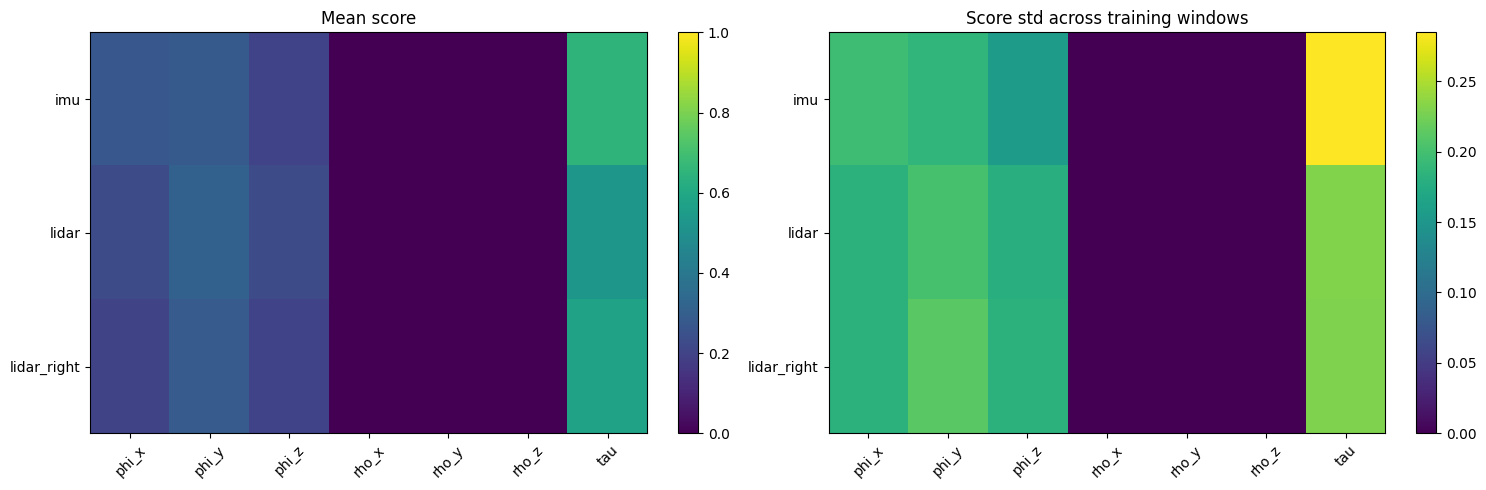

In [10]:
import pandas as pd

train_scores = train_target_cache.values.float()
score_rows = []
for calibration_id, key in enumerate(CALIBRATION_KEYS):
    for dof_id, dof in enumerate(OBSERVABILITY_PARAMETER_NAMES):
        values = train_scores[:, calibration_id, dof_id].numpy()
        score_rows.append({"sensor":key, "dof":dof, "mean":values.mean(), "std":values.std(), "p05":np.quantile(values,0.05), "p50":np.median(values), "p95":np.quantile(values,0.95)})
score_summary = pd.DataFrame(score_rows)
display(score_summary.round(4))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for axis, column, name in zip(axes, ("mean", "std"), ("Mean score", "Score std across training windows")):
    grid = score_summary.pivot(index="sensor", columns="dof", values=column).loc[list(CALIBRATION_KEYS), list(OBSERVABILITY_PARAMETER_NAMES)]
    image = axis.imshow(grid.to_numpy(), aspect="auto", vmin=0, vmax=1 if column=="mean" else None)
    axis.set_xticks(np.arange(7), OBSERVABILITY_PARAMETER_NAMES, rotation=45)
    axis.set_yticks(np.arange(3), CALIBRATION_KEYS)
    axis.set_title(name)
    fig.colorbar(image, ax=axis, fraction=0.046)
plt.tight_layout(); plt.show()

## 8. Stage 1b: error versus observability of the **original** correction predictor

Use matched paired perturbations on held-out physical windows, and bin the original model's signed correction errors by the cached unaugmented observability score. This is descriptive: the cached scores do **not** recompute at each perturbed prior. A correlation does not establish causality.

In [11]:
def make_augmentation_generator(seed: int):
    return torch.Generator(device=DEVICE.type).manual_seed(seed)


def clone_window_with_calibration(window: WindowBatch, calibration):
    return WindowBatch(
        streams=dict(window.streams),
        current_calibration=calibration,
        metadata=dict(window.metadata),
        targets=None if window.targets is None else dict(window.targets),
        dataset_indices=window.dataset_indices,
    )


def sample_pair_prior_deltas(true_calibration, *, generator: torch.Generator):
    """Sample exactly one canonical prior perturbation for each physical window."""
    _, delta_xi, delta_tau = pair_prior_perturber(true_calibration, generator=generator)
    return delta_xi, delta_tau


def make_paired_windows(base_window: WindowBatch, *, generator: torch.Generator, return_truth_window: bool = False):
    # Draw the true physical context only once so +/- priors share identical measurements.
    context_result = context_augmentation_pipeline(base_window, generator=generator)
    context_window = context_result.augmented_window
    true_calibration = context_window.current_calibration

    delta_xi_by_key, delta_tau_by_key = sample_pair_prior_deltas(true_calibration, generator=generator)
    positive_prior = apply_prior_perturbation(true_calibration, delta_xi_by_key, delta_tau_by_key)
    negative_prior = apply_prior_perturbation(true_calibration, {key: -value for key, value in delta_xi_by_key.items()}, {key: -value for key, value in delta_tau_by_key.items()})

    positive_window = clone_window_with_calibration(context_window, positive_prior)
    negative_window = clone_window_with_calibration(context_window, negative_prior)
    if return_truth_window:
        return positive_window, negative_window, context_window, delta_xi_by_key, delta_tau_by_key
    return positive_window, negative_window, delta_xi_by_key, delta_tau_by_key


def correction_target(window: WindowBatch, calibration_key: str):
    if window.targets is None:
        raise ValueError("Window has no calibration targets.")
    target = window.targets[calibration_key]
    current_state = window.current_calibration[calibration_key]
    if target.next_transform is None or target.next_time_offset is None:
        raise ValueError(f"Calibration target {calibration_key!r} does not contain the final calibration state.")

    target_delta_transform = target.next_transform @ torch.linalg.inv(current_state.transform)
    target_delta_xi = se3_log(target_delta_transform)
    target_delta_tau = target.next_time_offset - current_state.time_offset
    return target_delta_xi, target_delta_tau


In [12]:
def correction_regression_loss(prediction, target):
    if CORRECTION_LOSS_TYPE == "mse":
        return F.mse_loss(prediction, target)
    if CORRECTION_LOSS_TYPE == "smooth_l1":
        return F.smooth_l1_loss(prediction, target, beta=1.0)
    if CORRECTION_LOSS_TYPE == "l1":
        return F.l1_loss(prediction, target)
    raise ValueError(f"Unknown CORRECTION_LOSS_TYPE={CORRECTION_LOSS_TYPE!r}.")


def compute_training_loss(window, model_output):
    total_loss = torch.zeros((), dtype=MODEL_DTYPE, device=DEVICE)
    metrics = {}
    num_calibrations = 0

    for calibration_key, prediction in model_output.predictions.items():
        target_delta_xi, target_delta_tau = correction_target(window, calibration_key)

        rotation_loss = correction_regression_loss(prediction.delta_xi[:, :3] / ROTATION_LOSS_SCALE_RAD, target_delta_xi[:, :3] / ROTATION_LOSS_SCALE_RAD)
        translation_loss = correction_regression_loss(prediction.delta_xi[:, 3:] / TRANSLATION_LOSS_SCALE_M, target_delta_xi[:, 3:] / TRANSLATION_LOSS_SCALE_M)
        time_offset_loss = correction_regression_loss(prediction.delta_tau / TIME_OFFSET_LOSS_SCALE_S, target_delta_tau / TIME_OFFSET_LOSS_SCALE_S)

        calibration_loss = ROTATION_LOSS_WEIGHT * rotation_loss + TRANSLATION_LOSS_WEIGHT * translation_loss + TIME_OFFSET_LOSS_WEIGHT * time_offset_loss
        total_loss = total_loss + calibration_loss
        num_calibrations += 1

        rotation_error_rad = torch.linalg.vector_norm(prediction.delta_xi[:, :3] - target_delta_xi[:, :3], dim=-1)
        translation_error_m = torch.linalg.vector_norm(prediction.delta_xi[:, 3:] - target_delta_xi[:, 3:], dim=-1)
        time_offset_error_s = torch.abs(prediction.delta_tau[:, 0] - target_delta_tau[:, 0])

        metrics[f"{calibration_key}/rotation_error_deg"] = torch.rad2deg(rotation_error_rad).mean().item()
        metrics[f"{calibration_key}/translation_error_cm"] = (100.0 * translation_error_m).mean().item()
        metrics[f"{calibration_key}/time_offset_error_ms"] = (1000.0 * time_offset_error_s).mean().item()
        metrics[f"{calibration_key}/loss_rotation"] = rotation_loss.detach().item()
        metrics[f"{calibration_key}/loss_translation"] = translation_loss.detach().item()
        metrics[f"{calibration_key}/loss_time_offset"] = time_offset_loss.detach().item()

    if num_calibrations == 0:
        raise ValueError("Model produced no calibration predictions.")

    total_loss = total_loss / num_calibrations
    metrics["loss_total"] = total_loss.detach().item()
    return total_loss, metrics


def compute_pair_difference_loss(positive_window, positive_output, negative_window, negative_output):
    total_pair_loss = torch.zeros((), dtype=MODEL_DTYPE, device=DEVICE)
    metrics = {}
    num_calibrations = 0

    for calibration_key in CALIBRATION_KEYS:
        positive_prediction = positive_output.predictions[calibration_key]
        negative_prediction = negative_output.predictions[calibration_key]

        positive_target_xi, positive_target_tau = correction_target(positive_window, calibration_key)
        negative_target_xi, negative_target_tau = correction_target(negative_window, calibration_key)

        predicted_difference_xi = positive_prediction.delta_xi - negative_prediction.delta_xi
        target_difference_xi = positive_target_xi - negative_target_xi
        predicted_difference_tau = positive_prediction.delta_tau - negative_prediction.delta_tau
        target_difference_tau = positive_target_tau - negative_target_tau

        active_rotation_mask = torch.abs(target_difference_xi[:, :3]) > 1e-10

        if torch.any(active_rotation_mask):
            pair_rotation_loss = correction_regression_loss(predicted_difference_xi[:, :3][active_rotation_mask] / ROTATION_LOSS_SCALE_RAD, target_difference_xi[:, :3][active_rotation_mask] / ROTATION_LOSS_SCALE_RAD)
        else:
            pair_rotation_loss = torch.zeros((), dtype=MODEL_DTYPE, device=DEVICE)

        pair_translation_loss = correction_regression_loss(predicted_difference_xi[:, 3:] / TRANSLATION_LOSS_SCALE_M, target_difference_xi[:, 3:] / TRANSLATION_LOSS_SCALE_M)
        pair_time_offset_loss = correction_regression_loss(predicted_difference_tau / TIME_OFFSET_LOSS_SCALE_S, target_difference_tau / TIME_OFFSET_LOSS_SCALE_S)

        calibration_pair_loss = ROTATION_LOSS_WEIGHT * pair_rotation_loss + TRANSLATION_LOSS_WEIGHT * pair_translation_loss + TIME_OFFSET_LOSS_WEIGHT * pair_time_offset_loss
        total_pair_loss = total_pair_loss + calibration_pair_loss
        num_calibrations += 1

        metrics[f"{calibration_key}/pair_loss_rotation"] = pair_rotation_loss.detach().item()
        metrics[f"{calibration_key}/pair_loss_translation"] = pair_translation_loss.detach().item()
        metrics[f"{calibration_key}/pair_loss_time_offset"] = pair_time_offset_loss.detach().item()

    if num_calibrations == 0:
        raise ValueError("Model produced no calibration predictions.")

    total_pair_loss = total_pair_loss / num_calibrations
    metrics["loss_pair"] = total_pair_loss.detach().item()

    return total_pair_loss, metrics


def compute_paired_objective(positive_window, positive_output, negative_window, negative_output, truth_window=None, truth_output=None):
    positive_loss, positive_metrics = compute_training_loss(positive_window, positive_output)
    negative_loss, negative_metrics = compute_training_loss(negative_window, negative_output)
    pair_loss, pair_metrics = compute_pair_difference_loss(positive_window, positive_output, negative_window, negative_output)

    regular_loss = 0.5 * (positive_loss + negative_loss)

    if truth_window is not None or truth_output is not None:
        if truth_window is None or truth_output is None:
            raise ValueError("truth_window and truth_output must either both be provided or both be None.")

        truth_loss, truth_metrics = compute_training_loss(truth_window, truth_output)
    else:
        truth_loss = torch.zeros((), dtype=MODEL_DTYPE, device=DEVICE)
        truth_metrics = {}

    total_loss = regular_loss + PAIR_LOSS_WEIGHT * pair_loss + TRUTH_ANCHOR_LOSS_WEIGHT * truth_loss

    metrics = {
        "loss_total": total_loss.detach().item(),
        "loss_regular": regular_loss.detach().item(),
        "loss_pair": pair_loss.detach().item(),
        "loss_truth": truth_loss.detach().item(),
    }

    for key in positive_metrics:
        if key == "loss_total":
            continue

        metrics[f"positive/{key}"] = positive_metrics[key]
        metrics[f"negative/{key}"] = negative_metrics[key]
        metrics[f"mean/{key}"] = 0.5 * (positive_metrics[key] + negative_metrics[key])

    for key, value in truth_metrics.items():
        if key != "loss_total":
            metrics[f"truth/{key}"] = value

    metrics.update({f"pair/{key}": value for key, value in pair_metrics.items()})

    return total_loss, metrics

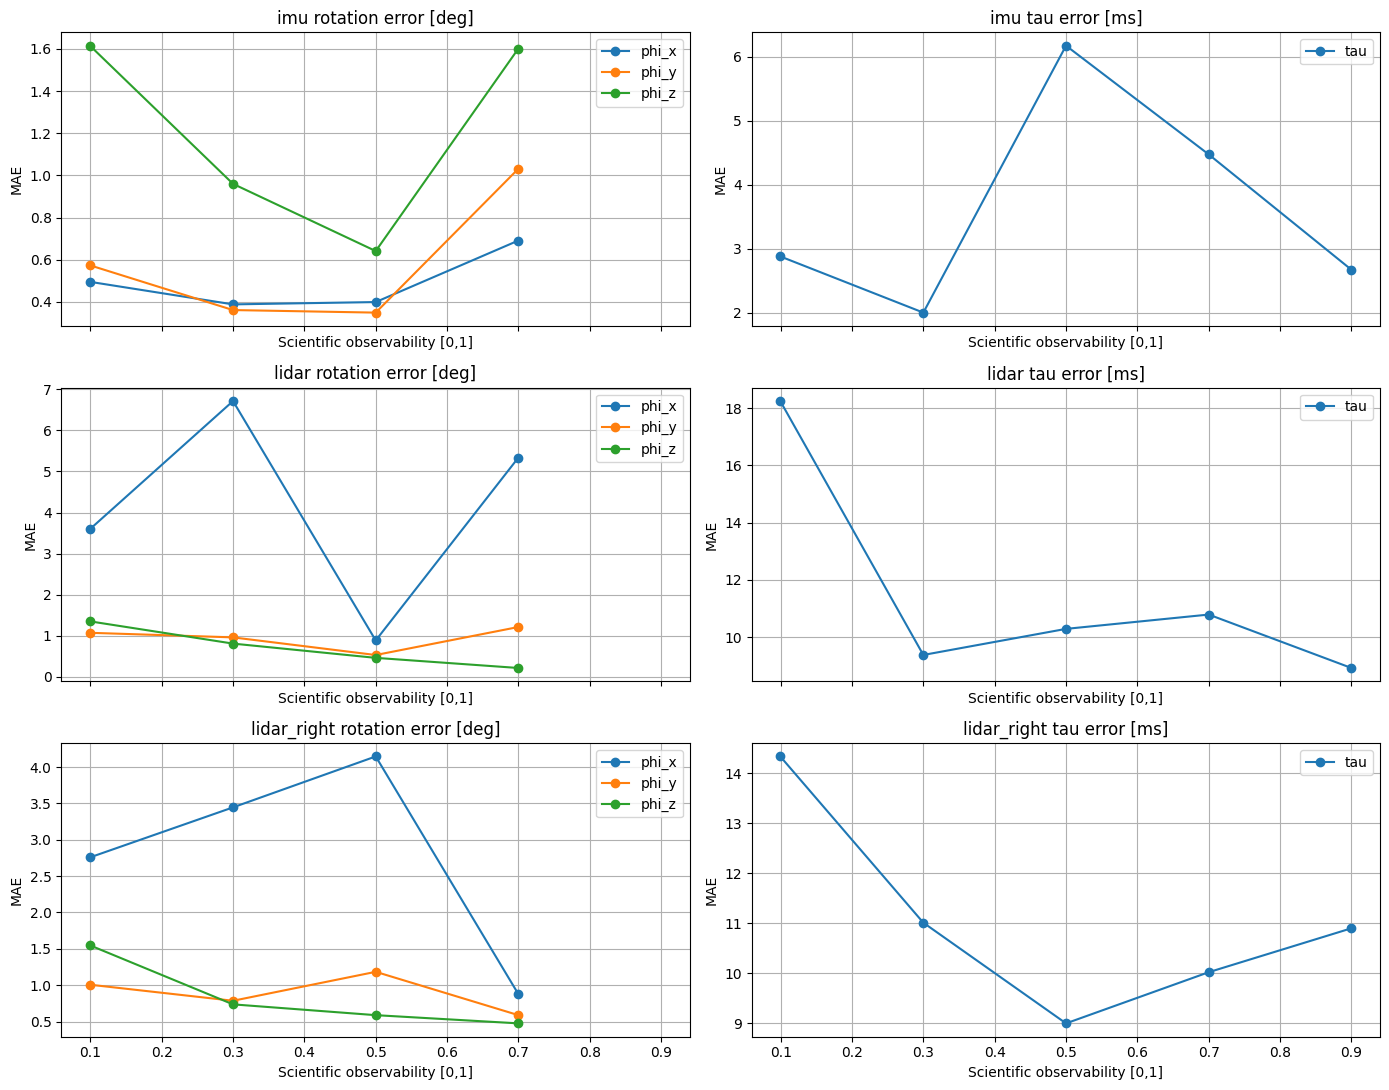

In [13]:
# Errors of the source model on fixed held-out ± pairs, stratified by original observability.
BIN_DIAGNOSTIC_MAX_WINDOWS = 128
BIN_DIAGNOSTIC_BATCH_SIZE = 8

source_model.eval()
error_rows = []
selected_indices = np.linspace(0, len(val_dataset)-1, min(BIN_DIAGNOSTIC_MAX_WINDOWS, len(val_dataset)), dtype=int)
bin_generator = make_augmentation_generator(VALIDATION_PAIR_SEED + 3100)
with torch.inference_mode():
    for start in range(0, len(selected_indices), BIN_DIAGNOSTIC_BATCH_SIZE):
        ids = selected_indices[start:start+BIN_DIAGNOSTIC_BATCH_SIZE]
        base_window = window_batch_to(collate_windows([val_dataset[int(i)] for i in ids]), DEVICE, dtype=MODEL_DTYPE)
        positive_window, negative_window, _, _ = make_paired_windows(base_window, generator=bin_generator)
        scores = val_target_cache.values[torch.as_tensor(base_window.dataset_indices).long().cpu()].numpy()
        for branch in (positive_window, negative_window):
            predictions = calibration_forward(branch).predictions
            for k, key in enumerate(CALIBRATION_KEYS):
                truth_xi, truth_tau = correction_target(branch, key)
                pred = predictions[key]
                errors = torch.cat(((pred.delta_xi[:, :3] - truth_xi[:, :3]).abs() * (180/np.pi), (pred.delta_tau-truth_tau).abs()*1000), dim=-1).cpu().numpy()
                for dof_idx, dof in enumerate(("phi_x", "phi_y", "phi_z", "tau")):
                    score_idx = (0,1,2,6)[dof_idx]
                    for score, error in zip(scores[:,k,score_idx], errors[:,dof_idx]):
                        error_rows.append((key, dof, float(score), float(error)))

error_by_score = pd.DataFrame(error_rows, columns=("sensor", "dof", "score", "abs_error"))
fig, axes = plt.subplots(3, 2, figsize=(14, 11), sharex=True)
for k, key in enumerate(CALIBRATION_KEYS):
    for col, selection in enumerate((("phi_x","phi_y","phi_z"),("tau",))):
        subset = error_by_score[(error_by_score.sensor==key) & error_by_score.dof.isin(selection)].copy()
        subset["bin"] = pd.cut(subset.score, bins=np.linspace(0,1,6), include_lowest=True)
        for dof in selection:
            series = subset[subset.dof==dof].groupby("bin", observed=True).abs_error.agg(("mean","count"))
            axes[k,col].plot([interval.mid for interval in series.index], series["mean"], marker="o", label=dof)
        axes[k,col].set_title(key + (" rotation error [deg]" if col==0 else " tau error [ms]"))
        axes[k,col].set_xlabel("Scientific observability [0,1]")
        axes[k,col].set_ylabel("MAE")
        axes[k,col].grid(True)
        axes[k,col].legend()
plt.tight_layout(); plt.show()

## 9. Stage 2: cache frozen 128D pooled features for *unaugmented* windows

One feature row and one scientific 7-score target per calibration. Features are extracted in original dataset order using the frozen source model. The cache is bound to the exact source checkpoint metadata so it cannot silently outlive the pretrained weights. **Do not recompute scientific targets for perturbed samples here.**

In [14]:
def feature_cache_metadata(dataset, split_name):
    source_stats = RESUME_CHECKPOINT.stat()
    return {"source_checkpoint":str(RESUME_CHECKPOINT.resolve()), "checkpoint_size":source_stats.st_size, "checkpoint_mtime_ns":source_stats.st_mtime_ns, "split":split_name, "num_windows":len(dataset), "calibration_keys":tuple(CALIBRATION_KEYS), "window_duration_s":WINDOW_DURATION_S, "window_stride_s":WINDOW_STRIDE_S, "feature_dim":SHARED_FEATURE_DIM, "sequence_names":tuple(dataset.sequence_name_for_window(i) for i in range(len(dataset))) if hasattr(dataset,"sequence_name_for_window") else None}


def load_or_extract_frozen_features(dataset, split_name):
    metadata = feature_cache_metadata(dataset, split_name)
    path = FEATURE_CACHE_DIR / f"{split_name}.pt"
    if path.is_file():
        saved = torch.load(path, map_location="cpu", weights_only=True)
        if isinstance(saved, dict) and saved.get("metadata")==metadata and isinstance(saved.get("features"), torch.Tensor) and saved["features"].shape==(len(dataset),len(CALIBRATION_KEYS),SHARED_FEATURE_DIM) and torch.isfinite(saved["features"]).all():
            print(f"Using verified {split_name} frozen features:", path)
            return saved["features"].float()
    features = torch.full((len(dataset),len(CALIBRATION_KEYS),SHARED_FEATURE_DIM), float("nan"), dtype=torch.float32)
    visited = torch.zeros(len(dataset), dtype=torch.bool)
    loader = make_kaist_dataloader(dataset, batch_size=BATCH_SIZE, shuffle=False, drop_last=False, num_workers=NUM_WORKERS)
    source_model.eval()
    with torch.inference_mode():
        for base_window in tqdm(loader, desc=f"Frozen {split_name} features"):
            indices = torch.as_tensor(base_window.dataset_indices).cpu().long()
            if torch.any(visited[indices]):
                raise ValueError(f"Duplicate dataset index in {split_name} loader.")
            window = window_batch_to(base_window, DEVICE, dtype=MODEL_DTYPE)
            pooled = calibration_forward(window).shared_features.detach().cpu().float()
            features[indices] = pooled
            visited[indices] = True
    if not torch.all(visited) or not torch.isfinite(features).all():
        raise ValueError(f"Incomplete or invalid frozen feature cache for {split_name}.")
    torch.save({"features":features, "metadata":metadata}, path)
    print(f"Saved {split_name} frozen features:", path)
    return features


frozen_train_features = load_or_extract_frozen_features(train_dataset, "train")
frozen_val_features = load_or_extract_frozen_features(val_dataset, "validation")
frozen_test_features = load_or_extract_frozen_features(test_dataset, "test")

for split, features, targets in (("train",frozen_train_features,train_target_cache.values),("validation",frozen_val_features,val_target_cache.values),("test",frozen_test_features,test_target_cache.values)):
    assert features.shape[:2]==targets.shape[:2] and targets.shape[-1]==7 and features.shape[-1]==128
    print(split, "features", tuple(features.shape), "targets", tuple(targets.shape))

Using verified train frozen features: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_pooled_calibration_paired_002.15_observability_output/frozen_features/train.pt
Using verified validation frozen features: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_pooled_calibration_paired_002.15_observability_output/frozen_features/validation.pt
Using verified test frozen features: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_pooled_calibration_paired_002.15_observability_output/frozen_features/test.pt
train features (2006, 3, 128) targets (2006, 3, 7)
validation features (418, 3, 128) targets (418, 3, 7)
test features (699, 3, 128) targets (699, 3, 7)


## 10. Stage 2: frozen probe, head-only training and constant-baseline evaluation

FROZEN BACKBONE / OBSERVABILITY HEAD GRADIENT CHECK: PASS | head grad norm=0.077465
Probe epoch   1/500 | train MSE=0.165360 val MSE=0.159249 LR=5.00e-04
Probe epoch  50/500 | train MSE=0.021194 val MSE=0.022764 LR=5.00e-04
Probe epoch 100/500 | train MSE=0.020012 val MSE=0.021776 LR=5.00e-04
Probe epoch 150/500 | train MSE=0.019506 val MSE=0.021824 LR=2.50e-04
Probe epoch 200/500 | train MSE=0.019428 val MSE=0.021792 LR=1.56e-05
Probe epoch 250/500 | train MSE=0.019421 val MSE=0.021790 LR=1.95e-06
Probe epoch 300/500 | train MSE=0.019420 val MSE=0.021791 LR=2.44e-07
Probe epoch 350/500 | train MSE=0.019420 val MSE=0.021791 LR=3.05e-08
Probe epoch 400/500 | train MSE=0.019420 val MSE=0.021791 LR=1.53e-08
Probe epoch 450/500 | train MSE=0.019420 val MSE=0.021791 LR=1.53e-08
Probe epoch 500/500 | train MSE=0.019420 val MSE=0.021791 LR=1.53e-08
Best frozen-head validation MSE: 0.02169126561847315
Head-only checkpoint: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_pooled

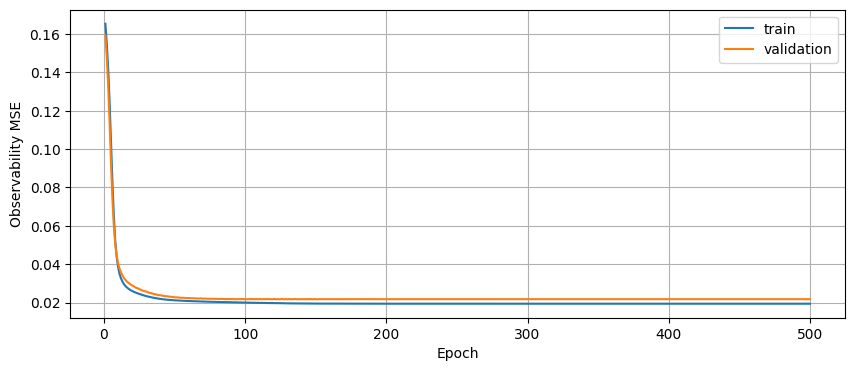

In [15]:
torch.manual_seed(RANDOM_SEED + 31)
observability_head = build_observability_head().to(DEVICE, dtype=MODEL_DTYPE)
probe_optimizer = torch.optim.AdamW(observability_head.parameters(), lr=PROBE_LR, weight_decay=1e-4)
probe_scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(probe_optimizer, mode="min", factor=0.5, patience=PROBE_PATIENCE)

probe_train_loader = DataLoader(TensorDataset(frozen_train_features,train_target_cache.values.float()),batch_size=PROBE_BATCH_SIZE,shuffle=True,generator=torch.Generator().manual_seed(RANDOM_SEED+500))
probe_val_loader = DataLoader(TensorDataset(frozen_val_features,val_target_cache.values.float()),batch_size=PROBE_BATCH_SIZE,shuffle=False)

# Gradient isolation: only the observability head is trainable; the source backbone stays immutable.
assert all(not parameter.requires_grad for parameter in source_model.parameters())
assert all(parameter.requires_grad for parameter in observability_head.parameters())


def probe_epoch(loader, *, training):
    observability_head.train(training)
    total_loss, total_count = 0.0, 0
    for features, targets in loader:
        features, targets = features.to(DEVICE,dtype=MODEL_DTYPE), targets.to(DEVICE,dtype=MODEL_DTYPE)
        with torch.set_grad_enabled(training):
            prediction = observability_head(features)
            loss = F.mse_loss(prediction, targets)
            if training:
                probe_optimizer.zero_grad(set_to_none=True)
                loss.backward()
                torch.nn.utils.clip_grad_norm_(observability_head.parameters(), GRADIENT_CLIP_NORM)
                probe_optimizer.step()
        total_loss += float(loss.detach())*len(features)
        total_count += len(features)
    return total_loss/max(total_count,1)


# Verify that gradients reach the new head while the pretrained correction backbone remains frozen.
smoke_features, smoke_targets = next(iter(probe_train_loader))
probe_optimizer.zero_grad(set_to_none=True)
smoke_loss = F.mse_loss(observability_head(smoke_features.to(DEVICE,dtype=MODEL_DTYPE)), smoke_targets.to(DEVICE,dtype=MODEL_DTYPE))
smoke_loss.backward()
probe_grad_norm = float(sum(parameter.grad.square().sum() for parameter in observability_head.parameters() if parameter.grad is not None).sqrt())
assert np.isfinite(probe_grad_norm) and probe_grad_norm > 0
assert all(parameter.grad is None for parameter in source_model.parameters())
probe_optimizer.zero_grad(set_to_none=True)
print(f"FROZEN BACKBONE / OBSERVABILITY HEAD GRADIENT CHECK: PASS | head grad norm={probe_grad_norm:.6f}")
del smoke_features, smoke_targets, smoke_loss

probe_best_path = RUN_DIR / "frozen_observability_head_best.pt"
probe_last_path = RUN_DIR / "frozen_observability_head_last.pt"

probe_experiment_snapshot = {
    "run_name": RUN_NAME,
    "stage": "frozen_observability_head",
    "architecture": "PooledCalibrationModel + shared 128-128-7 head",
    "source_checkpoint": str(RESUME_CHECKPOINT),
    "source_model_config": source_model_config,
    "windowing_config": windowing_config,
    "rig_calibration": rig_calibration,
    "calibration_keys": CALIBRATION_KEYS,
    "observability_cache_directory": str(OBSERVABILITY_CACHE_DIR),
    "observability_cache_version": OBSERVABILITY_CACHE_VERSION,
    "observability_source": OBSERVABILITY_SOURCE,
    "observability_targets_are_unaugmented": True,
    "output_parameter_order": OBSERVABILITY_PARAMETER_NAMES,
    "head_input_dim": SHARED_FEATURE_DIM,
    "head_hidden_dim": PROBE_HIDDEN_DIM,
    "head_output_dim": OBSERVABILITY_TOKEN_FEATURE_DIM,
    "train_sequences": tuple(TRAIN_NAMES),
    "validation_sequences": tuple(VAL_NAMES),
    "test_sequences": tuple(TEST_NAMES),
}


def save_probe_checkpoint(path, epoch, train_loss, val_loss):
    torch.save({
        "observability_head": observability_head.state_dict(),
        "epoch": epoch,
        "train_mse": train_loss,
        "validation_mse": val_loss,
        "experiment": probe_experiment_snapshot,
    }, path)
probe_best_validation = float("inf")
probe_history = []
for epoch in range(1,PROBE_EPOCHS+1):
    train_loss = probe_epoch(probe_train_loader,training=True)
    val_loss = probe_epoch(probe_val_loader,training=False)
    probe_scheduler.step(val_loss)
    probe_history.append((epoch,train_loss,val_loss))
    if val_loss < probe_best_validation:
        probe_best_validation = val_loss
        save_probe_checkpoint(probe_best_path, epoch, train_loss, val_loss)
    if epoch % 50 == 0 or epoch == PROBE_EPOCHS:
        save_probe_checkpoint(probe_last_path, epoch, train_loss, val_loss)
    if epoch==1 or epoch%50==0 or epoch==PROBE_EPOCHS:
        print(f"Probe epoch {epoch:3d}/{PROBE_EPOCHS} | train MSE={train_loss:.6f} val MSE={val_loss:.6f} LR={probe_optimizer.param_groups[0]['lr']:.2e}")

probe_payload = torch.load(probe_best_path,map_location=DEVICE,weights_only=False)  # Trusted local checkpoint contains the experiment dataclasses.
observability_head.load_state_dict(probe_payload["observability_head"])
observability_head.eval()
print("Best frozen-head validation MSE:",probe_best_validation)
print("Head-only checkpoint:",probe_best_path)
assert all(not parameter.requires_grad for parameter in source_model.parameters())

plt.figure(figsize=(10,4));plt.plot([r[0] for r in probe_history],[r[1] for r in probe_history],label="train");plt.plot([r[0] for r in probe_history],[r[2] for r in probe_history],label="validation");plt.xlabel("Epoch");plt.ylabel("Observability MSE");plt.grid(True);plt.legend();plt.show()

## 11. Per-calibration, per-DOF observability metrics

Evaluate on **unseen** Urban26/28 and Urban38/39. R² is measured against each coordinate's evaluation-set mean, while `MSE_vs_train_mean` compares against the deployable constant predictor learned from **training only**. Small score variance can make R² unstable; show target std and the baseline explicitly.

In [16]:
@torch.inference_mode()
def probe_predict(features, *, head=None, batch_size=PROBE_BATCH_SIZE):
    if head is None:
        head = observability_head
    head.eval()
    return torch.cat([head(features[i:i+batch_size].to(DEVICE,dtype=MODEL_DTYPE)).cpu() for i in range(0,len(features),batch_size)],dim=0)


def observability_metrics(predicted, truth, train_means):
    predicted, truth, train_means = predicted.float().numpy(),truth.float().numpy(),train_means.float().numpy()
    rows=[]
    for k,key in enumerate(CALIBRATION_KEYS):
        for j,dof in enumerate(OBSERVABILITY_PARAMETER_NAMES):
            p,t=predicted[:,k,j],truth[:,k,j]
            mse=float(np.mean((p-t)**2)); mae=float(np.mean(np.abs(p-t))); baseline=float(np.mean((t-train_means[k,j])**2))
            variance=float(np.mean((t-t.mean())**2))
            r2=(1-mse/variance) if variance>1e-10 else np.nan
            pearson=float(np.corrcoef(p,t)[0,1]) if np.std(p)>1e-7 and np.std(t)>1e-7 else np.nan
            rows.append({"sensor":key,"dof":dof,"MSE":mse,"MAE":mae,"R2":r2,"Pearson":pearson,"target_std":float(np.std(t)),"train_mean_MSE":baseline,"MSE_vs_train_mean":mse/max(baseline,1e-12)})
    return pd.DataFrame(rows)

train_score_mean = train_target_cache.values.mean(dim=0)
probe_val_pred = probe_predict(frozen_val_features)
probe_test_pred = probe_predict(frozen_test_features)
probe_val_metrics = observability_metrics(probe_val_pred,val_target_cache.values,train_score_mean)
probe_test_metrics = observability_metrics(probe_test_pred,test_target_cache.values,train_score_mean)

print("VALIDATION metrics (21 coordinates):")
display(probe_val_metrics.round(4))
print("TEST metrics (21 coordinates):")
display(probe_test_metrics.round(4))
print("Validation mean MSE vs train-mean:",probe_val_metrics.MSE.mean(),"/",probe_val_metrics.train_mean_MSE.mean())
print("Test mean MSE vs train-mean:",probe_test_metrics.MSE.mean(),"/",probe_test_metrics.train_mean_MSE.mean())
probe_val_metrics.to_csv(RUN_DIR/"frozen_probe_validation_metrics.csv",index=False)
probe_test_metrics.to_csv(RUN_DIR/"frozen_probe_test_metrics.csv",index=False)

VALIDATION metrics (21 coordinates):


,sensor,dof,MSE,MAE,R2,Pearson,target_std,train_mean_MSE,MSE_vs_train_mean
0,imu,phi_x,0.0449,0.1715,-0.1408,0.1857,0.1984,0.0437,1.027900e+00
1,imu,phi_y,0.0355,0.1518,0.0099,0.1790,0.1895,0.0374,9.497000e-01
2,imu,phi_z,0.0216,0.1190,0.0736,0.2754,0.1528,0.0240,9.024000e-01
3,imu,rho_x,0.0001,0.0072,NaN,NaN,0.0000,0.0000,5.930246e+07
4,imu,rho_y,0.0000,0.0067,NaN,NaN,0.0000,0.0000,4.950386e+07
5,imu,rho_z,0.0001,0.0068,NaN,NaN,0.0000,0.0000,5.351266e+07
6,imu,tau,0.1015,0.2957,-0.1263,0.4237,0.3003,0.1075,9.445000e-01
7,lidar,phi_x,0.0281,0.1315,0.2202,0.5264,0.1900,0.0395,7.124000e-01
8,lidar,phi_y,0.0327,0.1571,0.2400,0.5045,0.2076,0.0431,7.600000e-01
9,lidar,phi_z,0.0270,0.1351,0.1869,0.4428,0.1821,0.0332,8.117000e-01


TEST metrics (21 coordinates):


,sensor,dof,MSE,MAE,R2,Pearson,target_std,train_mean_MSE,MSE_vs_train_mean
0,imu,phi_x,0.0473,0.1775,-0.2594,0.0076,0.1938,0.0436,1.085700e+00
1,imu,phi_y,0.0387,0.1592,-0.0954,-0.0272,0.1881,0.0377,1.027300e+00
2,imu,phi_z,0.0229,0.1243,-0.0364,0.0744,0.1488,0.0229,1.001800e+00
3,imu,rho_x,0.0001,0.0069,NaN,NaN,0.0000,0.0000,5.295136e+07
4,imu,rho_y,0.0000,0.0064,NaN,NaN,0.0000,0.0000,4.478548e+07
5,imu,rho_z,0.0000,0.0065,NaN,NaN,0.0000,0.0000,4.781046e+07
6,imu,tau,0.1024,0.2886,-0.2302,0.1047,0.2885,0.0946,1.081900e+00
7,lidar,phi_x,0.0293,0.1317,0.1413,0.4621,0.1848,0.0387,7.578000e-01
8,lidar,phi_y,0.0364,0.1644,0.1805,0.4512,0.2106,0.0451,8.065000e-01
9,lidar,phi_z,0.0304,0.1423,0.1697,0.4475,0.1914,0.0371,8.188000e-01


Validation mean MSE vs train-mean: 0.02169126540285929 / 0.026412647720028763
Test mean MSE vs train-mean: 0.022435287036170763 / 0.026248617922245462


### 11a. Negative control: shuffle frozen physical-window features

In [17]:
# Does the frozen head actually use window-specific representations, or only sensor-wise mean scores?
# Keep the target at its original physical window, and permute complete per-window features.
# A successful probe should beat the train-mean baseline and degrade on shuffled features.

PROBE_SHUFFLE_SEED = RANDOM_SEED + 310001
permutation_rng = np.random.default_rng(PROBE_SHUFFLE_SEED)
permutation = torch.as_tensor(permutation_rng.permutation(len(frozen_test_features)), dtype=torch.long)

if len(permutation) > 1 and torch.equal(permutation, torch.arange(len(permutation))):
    permutation = permutation.roll(1)

shuffled_feature_predictions = probe_predict(frozen_test_features[permutation])
shuffled_probe_mse = F.mse_loss(shuffled_feature_predictions, test_target_cache.values.float()).item()
correct_probe_mse = F.mse_loss(probe_test_pred, test_target_cache.values.float()).item()
constant_probe_mse = F.mse_loss(train_score_mean.unsqueeze(0).expand_as(test_target_cache.values), test_target_cache.values.float()).item()

print("FROZEN OBSERVABILITY PROBE INPUT DEPENDENCE")
print(f"  correct physical window features  MSE: {correct_probe_mse:.8f}")
print(f"  shuffled physical window features MSE: {shuffled_probe_mse:.8f}")
print(f"  per-sensor/DOF train-mean baseline MSE: {constant_probe_mse:.8f}")
print(f"  shuffled / correct MSE: {shuffled_probe_mse/max(correct_probe_mse,1e-12):.3f}x")
print("If correct is not better than both shuffled and constant, the head has not learned useful window-specific observability.")


FROZEN OBSERVABILITY PROBE INPUT DEPENDENCE
  correct physical window features  MSE: 0.02243529
  shuffled physical window features MSE: 0.03031703
  per-sensor/DOF train-mean baseline MSE: 0.02624862
  shuffled / correct MSE: 1.351x
If correct is not better than both shuffled and constant, the head has not learned useful window-specific observability.


## 12. Frozen-probe prediction plots

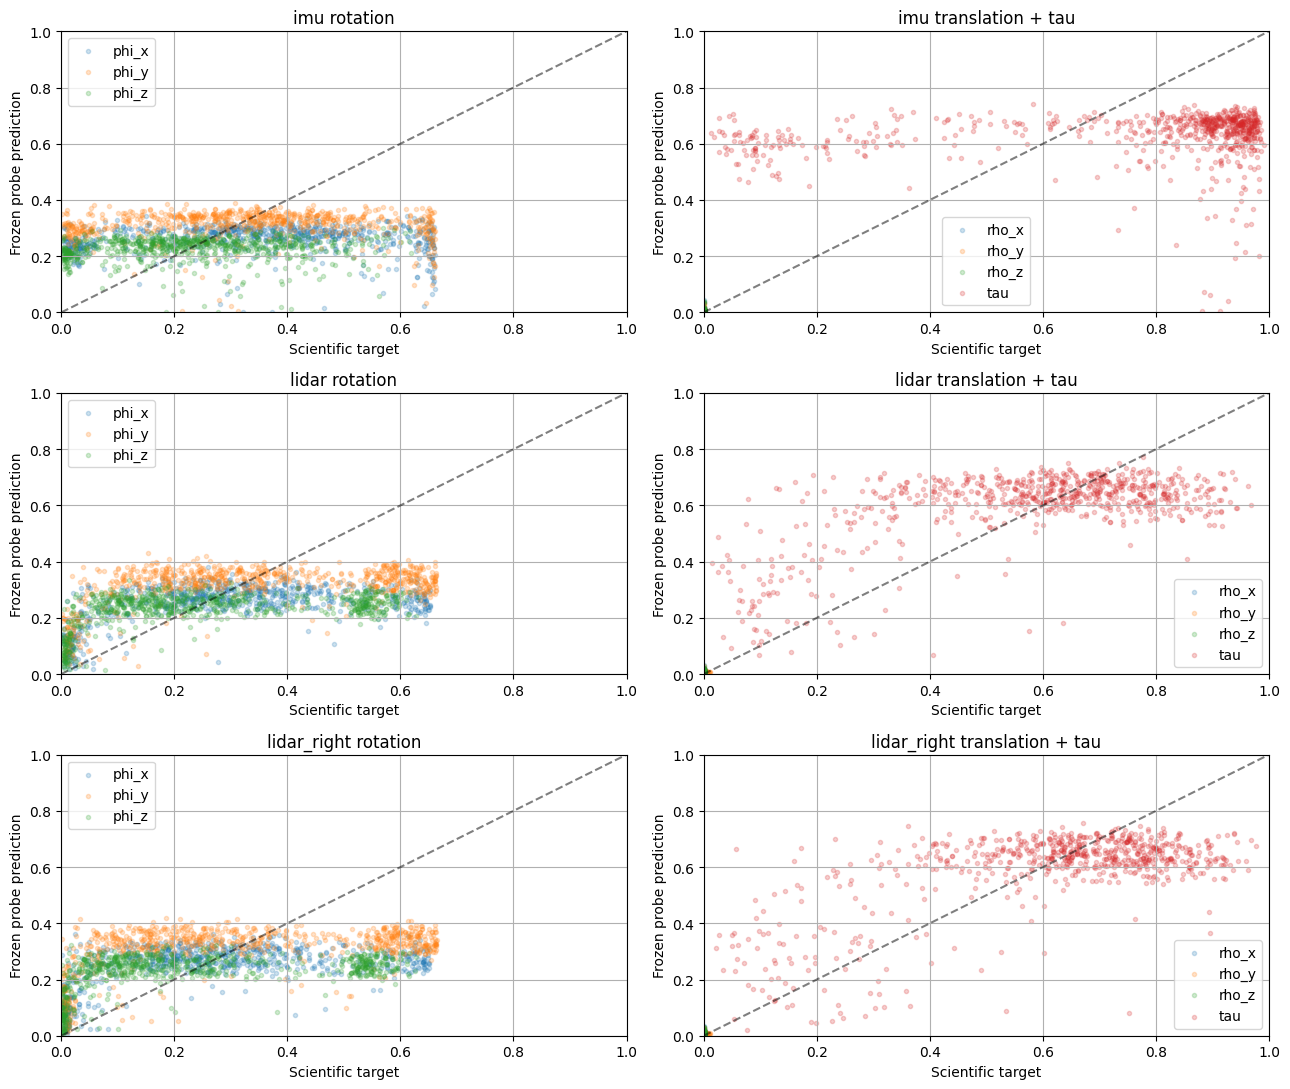

In [18]:
fig, axes = plt.subplots(len(CALIBRATION_KEYS),2,figsize=(13,11))
for k,key in enumerate(CALIBRATION_KEYS):
    for col, dofs in enumerate(((0,1,2),(3,4,5,6))):
        axis=axes[k,col]
        for j in dofs:
            true=test_target_cache.values[:,k,j].numpy()
            predicted=probe_test_pred[:,k,j].numpy()
            axis.scatter(true,predicted,s=9,alpha=0.22,label=OBSERVABILITY_PARAMETER_NAMES[j])
        axis.plot([0,1],[0,1],"k--",alpha=0.5)
        axis.set_xlim(0,1);axis.set_ylim(0,1)
        axis.set_xlabel("Scientific target");axis.set_ylabel("Frozen probe prediction")
        axis.set_title(key+(" rotation" if col==0 else " translation + tau"))
        axis.grid(True);axis.legend()
plt.tight_layout();plt.show()

## 13. Stage 2 conclusion gate

The mean-score baseline is an essential control. If the head does **not** improve held-out MSE or R² over that baseline, the frozen representation may not carry useful window-wise information about scientific observability. A successful probe does **not** prove the correction head actually uses observability: Stage 3 tests whether joint supervision improves correction without sacrificing the existing model.

In [19]:
probe_beats_baseline_validation = probe_val_metrics.MSE.mean()<probe_val_metrics.train_mean_MSE.mean()
probe_beats_baseline_test = probe_test_metrics.MSE.mean()<probe_test_metrics.train_mean_MSE.mean()
print("Frozen probe improves train-mean baseline on validation:", probe_beats_baseline_validation)
print("Frozen probe improves train-mean baseline on test:", probe_beats_baseline_test)
print("Joint fine-tuning enabled:", RUN_JOINT_FINETUNING)

Frozen probe improves train-mean baseline on validation: True
Frozen probe improves train-mean baseline on test: True
Joint fine-tuning enabled: True


## 14. Stage 3 (optional): joint calibration + observability supervision

**Only runs with `RUN_JOINT_FINETUNING=True`.** Starts from `002.10` plus the trained frozen probe, not from the previous `002.14` input model. The full existing paired correction objective is unchanged. An additional observability MSE is evaluated on the **original unaugmented base window**, which matches the cached scientific target. The correction-only matched control begins from the same `002.10` weights and sees **exactly the same paired augmented windows**. The source model remains untouched.

For GPU memory, backpropagate the paired correction loss first and release its graph, then separately forward/backpropagate the unaugmented observability loss before a single optimizer step. This avoids retaining all three forward graphs at once.

In [20]:
# Preserve the source. The joint wrapper can be reconstructed from its checkpoint via this class.
joint_model = CalibrationWithObservability(copy.deepcopy(source_model),copy.deepcopy(observability_head)).to(DEVICE,dtype=MODEL_DTYPE)
joint_model.requires_grad_(True)
control_model = copy.deepcopy(source_model).to(DEVICE,dtype=MODEL_DTYPE).requires_grad_(True)
source_model.eval().requires_grad_(False)


def forward_joint(window, module):
    return calibration_forward(window,backbone=module.calibration_model)


# Before joint training the *correction* predictions are still identical to source 002.10.
joint_model.eval(); control_model.eval(); source_model.eval()
with torch.inference_mode():
    check_window=window_batch_to(collate_windows([val_dataset[i] for i in range(2)]),DEVICE,dtype=MODEL_DTYPE)
    original=calibration_forward(check_window,backbone=source_model)
    joint_initial=forward_joint(check_window,joint_model)
    control_initial=calibration_forward(check_window,backbone=control_model)
    for key in CALIBRATION_KEYS:
        for other in (joint_initial,control_initial):
            torch.testing.assert_close(other.predictions[key].delta_xi,original.predictions[key].delta_xi,atol=1e-6,rtol=1e-5)
            torch.testing.assert_close(other.predictions[key].delta_tau,original.predictions[key].delta_tau,atol=1e-6,rtol=1e-5)
print("JOINT + CORRECTION-ONLY ZERO-STEP PREDICTION EQUIVALENCE: PASS")
del original,joint_initial,control_initial,check_window

JOINT + CORRECTION-ONLY ZERO-STEP PREDICTION EQUIVALENCE: PASS


## 15. Stage 3 metrics and one-epoch training/evaluation functions

In [21]:

def accumulate_metrics(metric_sums, metrics, batch_size):
    for key, value in metrics.items():
        metric_sums[key] = metric_sums.get(key, 0.0) + float(value) * batch_size


def normalize_metrics(metric_sums, num_samples):
    return {key: value / max(num_samples, 1) for key, value in metric_sums.items()}


def run_joint_epoch(loader, *, training, seed, optimizers=None, include_control=False, score_cache=None):
    '''Run joint calibration/observability training with an optional correction-only control.'''
    joint_model.train(training)

    if include_control:
        control_model.train(training)

    if training and (optimizers is None or "joint" not in optimizers):
        raise ValueError("Training requires a joint optimizer.")

    if score_cache is None:
        score_cache = train_target_cache if loader is train_loader else val_target_cache if loader is val_loader else test_target_cache

    pair_generator = make_augmentation_generator(seed)
    totals_joint, totals_control, count = {}, {}, 0

    for base_window in loader:
        base_window = window_batch_to(base_window, DEVICE, dtype=MODEL_DTYPE)
        pos, neg, _, _ = make_paired_windows(base_window, generator=pair_generator)

        indices = torch.as_tensor(base_window.dataset_indices).cpu().long()
        targets = score_cache.values[indices].to(DEVICE, dtype=MODEL_DTYPE)

        if training:
            optimizers["joint"].zero_grad(set_to_none=True)

        # Calibration correction: two paired forward passes.
        with torch.set_grad_enabled(training):
            pos_result = forward_joint(pos, joint_model)
            neg_result = forward_joint(neg, joint_model)
            correction_loss, metrics_joint = compute_paired_objective(pos, pos_result, neg, neg_result)

            if training:
                correction_loss.backward()

        del pos_result, neg_result

        # Observability prediction: one additional forward pass on the original physical window.
        with torch.set_grad_enabled(training):
            raw_result = forward_joint(base_window, joint_model)
            predicted_scores = joint_model.observability_head(raw_result.shared_features)
            obs_loss = F.mse_loss(predicted_scores, targets)

            if training:
                (OBS_AUX_LOSS_WEIGHT * obs_loss).backward()

        del raw_result, predicted_scores

        if training:
            torch.nn.utils.clip_grad_norm_(joint_model.parameters(), GRADIENT_CLIP_NORM)
            optimizers["joint"].step()

        metrics_joint["loss_observability"] = float(obs_loss.detach())
        metrics_joint["loss_joint_total"] = float(correction_loss.detach()) + OBS_AUX_LOSS_WEIGHT * float(obs_loss.detach())

        batch_size = targets.shape[0]
        accumulate_metrics(totals_joint, metrics_joint, batch_size)

        # Completely skip the second model when disabled.
        if include_control:
            if training:
                optimizers["control"].zero_grad(set_to_none=True)

            with torch.set_grad_enabled(training):
                pos_control = calibration_forward(pos, backbone=control_model)
                neg_control = calibration_forward(neg, backbone=control_model)
                control_loss, metrics_control = compute_paired_objective(pos, pos_control, neg, neg_control)

                if training:
                    control_loss.backward()
                    torch.nn.utils.clip_grad_norm_(control_model.parameters(), GRADIENT_CLIP_NORM)
                    optimizers["control"].step()

            accumulate_metrics(totals_control, metrics_control, batch_size)
            del pos_control, neg_control, control_loss

        count += batch_size
        del correction_loss, obs_loss, pos, neg, base_window

    joint_metrics = normalize_metrics(totals_joint, count)
    control_metrics = normalize_metrics(totals_control, count) if include_control else None

    return joint_metrics, control_metrics


## 16. Optional joint training, matched correction-only control, checkpoint snapshots

In [25]:
torch.cuda.empty_cache()

In [23]:
import time
import gc

JOINT_BEST_PATH = RUN_DIR / "joint_best.pt"
JOINT_LAST_PATH = RUN_DIR / "joint_last.pt"
CONTROL_BEST_PATH = RUN_DIR / "correction_control_best.pt"
CONTROL_LAST_PATH = RUN_DIR / "correction_control_last.pt"

RUN_CONTROL = False
RUN_MATCHED_CORRECTION_ONLY_CONTROL = RUN_CONTROL

# Set True after restarting the notebook to restore the latest completed epoch.
RESUME_JOINT_TRAINING = True
JOINT_RESUME_PATH = JOINT_LAST_PATH
CONTROL_RESUME_PATH = CONTROL_LAST_PATH

EXPERIMENT_SNAPSHOT = {
    "run_name": RUN_NAME,
    "architecture": "CalibrationWithObservability",
    "source_checkpoint": str(RESUME_CHECKPOINT),
    "model_config": source_model_config,
    "windowing_config": windowing_config,
    "rig_calibration": rig_calibration,
    "calibration_keys": CALIBRATION_KEYS,
    "measurement_dim": MEASUREMENT_DIM,
    "input_token_dim": BASE_TOKEN_INPUT_DIM,
    "observability_output_dim": OBSERVABILITY_TOKEN_FEATURE_DIM,
    "observability_head_hidden_dim": PROBE_HIDDEN_DIM,
    "observability_head_state": "shared_pretrained_frozen_probe",
    "observability_source": OBSERVABILITY_SOURCE,
    "observability_cache_directory": str(OBSERVABILITY_CACHE_DIR),
    "observability_cache_version": OBSERVABILITY_CACHE_VERSION,
    "observability_targets_are_unaugmented": True,
    "pair_prior_config": pair_prior_config,
    "context_augmentation_config": context_augmentation_config,
    "pair_loss_weight": PAIR_LOSS_WEIGHT,
    "observability_aux_loss_weight": OBS_AUX_LOSS_WEIGHT,
    "true_calibration_augmentation": True,
    "calibration_model_output_shape": "shared_features[B,3,128]",
    "sequence_split": {"train": tuple(TRAIN_NAMES), "validation": tuple(VAL_NAMES), "test": tuple(TEST_NAMES)},
    "probe_checkpoint": str(probe_best_path),
    "run_control": RUN_CONTROL,
    "stage": "joint_finetuning",
}

joint_history = []

if RUN_JOINT_FINETUNING:
    joint_optimizer = torch.optim.AdamW(joint_model.parameters(), lr=JOINT_LR, weight_decay=WEIGHT_DECAY)
    joint_scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(joint_optimizer, mode="min", factor=0.5, patience=JOINT_PATIENCE)

    control_optimizer = None
    control_scheduler = None
    if RUN_CONTROL:
        control_model.to(DEVICE, dtype=MODEL_DTYPE)
        control_optimizer = torch.optim.AdamW(control_model.parameters(), lr=JOINT_LR, weight_decay=WEIGHT_DECAY)
        control_scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(control_optimizer, mode="min", factor=0.5, patience=JOINT_PATIENCE)
    else:
        control_model.cpu()
        if DEVICE.type == "cuda":
            torch.cuda.empty_cache()

    start_epoch = 0
    global_step = 0
    best_joint_regular = float("inf")
    best_control_regular = float("inf")

    if RESUME_JOINT_TRAINING:
        if not JOINT_RESUME_PATH.is_file():
            raise FileNotFoundError(f"Joint training resume checkpoint not found: {JOINT_RESUME_PATH}")

        checkpoint = load_training_checkpoint(
            JOINT_RESUME_PATH,
            model=joint_model,
            optimizer=joint_optimizer,
            scheduler=joint_scheduler,
            generators={"train_shuffle": train_shuffle_generator},
            map_location=DEVICE,
            restore_rng_state=True,
        )
        start_epoch = int(checkpoint.get("epoch", 0))
        global_step = int(checkpoint.get("global_step", start_epoch * len(train_loader)))
        extra_state = checkpoint.get("extra_state") or {}
        best_joint_regular = float(extra_state.get("best_validation_loss", float("inf")))
        joint_history = list(extra_state.get("joint_history", []))
        if not joint_optimizer.state:
            raise RuntimeError("Joint optimizer state is empty after resume; expected a full training checkpoint, not weights only.")

        if RUN_CONTROL:
            if not CONTROL_RESUME_PATH.is_file():
                raise FileNotFoundError(f"Control training resume checkpoint not found: {CONTROL_RESUME_PATH}")
            control_checkpoint = load_training_checkpoint(
                CONTROL_RESUME_PATH,
                model=control_model,
                optimizer=control_optimizer,
                scheduler=control_scheduler,
                map_location=DEVICE,
                restore_rng_state=False,
            )
            control_epoch = int(control_checkpoint.get("epoch", 0))
            if control_epoch != start_epoch:
                raise ValueError(f"Joint and control resume epochs differ: {start_epoch} vs {control_epoch}")
            best_control_regular = float((control_checkpoint.get("extra_state") or {}).get("best_validation_loss", float("inf")))
            if not control_optimizer.state:
                raise RuntimeError("Control optimizer state is empty after resume.")

        print(f"Resumed from {JOINT_RESUME_PATH} | completed epoch={start_epoch} | global step={global_step}")
    else:
        print("Starting joint training from currently initialized model weights and a fresh optimizer.")

    print(f"Correction-only control: {'ON' if RUN_CONTROL else 'OFF'} | LR={joint_optimizer.param_groups[0]['lr']:.3e}")

    for epoch in range(start_epoch + 1, JOINT_EPOCHS + 1):
        optimizers = {"joint": joint_optimizer}
        if RUN_CONTROL:
            optimizers["control"] = control_optimizer

        train_start = time.perf_counter()
        train_joint, train_control = run_joint_epoch(train_loader, training=True, seed=TRAIN_PAIR_SEED + epoch, optimizers=optimizers, include_control=RUN_CONTROL)
        if DEVICE.type == "cuda":
            torch.cuda.synchronize()
        train_seconds = time.perf_counter() - train_start

        val_start = time.perf_counter()
        val_joint, val_control = run_joint_epoch(val_loader, training=False, seed=VALIDATION_PAIR_SEED, include_control=RUN_CONTROL)
        if DEVICE.type == "cuda":
            torch.cuda.synchronize()
        val_seconds = time.perf_counter() - val_start

        joint_scheduler.step(val_joint["loss_regular"])
        if RUN_CONTROL:
            control_scheduler.step(val_control["loss_regular"])

        global_step += len(train_loader)
        joint_history.append({"epoch": epoch, "joint_train": train_joint, "joint_val": val_joint, "control_train": train_control, "control_val": val_control, "train_seconds": train_seconds, "val_seconds": val_seconds})

        saved = []
        if val_joint["loss_regular"] < best_joint_regular:
            best_joint_regular = val_joint["loss_regular"]
            save_training_checkpoint(JOINT_BEST_PATH, model=joint_model, optimizer=joint_optimizer, scheduler=joint_scheduler, epoch=epoch, global_step=global_step, metrics=val_joint, generators={"train_shuffle": train_shuffle_generator}, extra_state={"best_validation_loss": best_joint_regular, "experiment": EXPERIMENT_SNAPSHOT, "joint_history": joint_history})
            saved.append("joint best")

        if RUN_CONTROL and val_control["loss_regular"] < best_control_regular:
            best_control_regular = val_control["loss_regular"]
            save_training_checkpoint(CONTROL_BEST_PATH, model=control_model, optimizer=control_optimizer, scheduler=control_scheduler, epoch=epoch, global_step=global_step, metrics=val_control, extra_state={"best_validation_loss": best_control_regular, "experiment": {**EXPERIMENT_SNAPSHOT, "architecture": "PooledCalibrationModel", "stage": "matched_correction_only_control"}})
            saved.append("control best")

        # Save every completed epoch so an interruption only repeats an unfinished epoch.
        save_training_checkpoint(JOINT_LAST_PATH, model=joint_model, optimizer=joint_optimizer, scheduler=joint_scheduler, epoch=epoch, global_step=global_step, metrics=val_joint, generators={"train_shuffle": train_shuffle_generator}, extra_state={"best_validation_loss": best_joint_regular, "experiment": EXPERIMENT_SNAPSHOT, "joint_history": joint_history})
        saved.append("joint last")
        if RUN_CONTROL:
            save_training_checkpoint(CONTROL_LAST_PATH, model=control_model, optimizer=control_optimizer, scheduler=control_scheduler, epoch=epoch, global_step=global_step, metrics=val_control, extra_state={"best_validation_loss": best_control_regular, "experiment": {**EXPERIMENT_SNAPSHOT, "architecture": "PooledCalibrationModel", "stage": "matched_correction_only_control"}})
            saved.append("control last")

        print(
            f"Epoch {epoch:3d}/{JOINT_EPOCHS} | joint val regular={val_joint['loss_regular']:.6f} obs={val_joint['loss_observability']:.6f} "
            f"lr={joint_optimizer.param_groups[0]['lr']:.3e} | "
            + (f"control val regular={val_control['loss_regular']:.6f} lr={control_optimizer.param_groups[0]['lr']:.3e} | " if RUN_CONTROL else "")
            + f"train={train_seconds:.1f}s val={val_seconds:.1f}s | Saved: {', '.join(saved)}"
        )

        # Keep the last optimizer/model state in memory to allow restarting the training cell.
        # Load JOINT_BEST_PATH separately when you want to evaluate the best validation checkpoint.
        gc.collect()
        if DEVICE.type == "cuda":
            torch.cuda.synchronize()
            torch.cuda.empty_cache()
else:
    print("Joint training skipped. Set RUN_JOINT_FINETUNING=True to enable it.")


Resumed from /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_pooled_calibration_paired_002.15_observability_output/joint_last.pt | completed epoch=87 | global step=10875
Correction-only control: OFF | LR=1.500e-04
Epoch  88/200 | joint val regular=0.847521 obs=0.005782 lr=1.500e-04 | train=278.9s val=182.1s | Saved: joint last
Epoch  89/200 | joint val regular=0.861836 obs=0.006170 lr=1.500e-04 | train=335.0s val=89.1s | Saved: joint last
Epoch  90/200 | joint val regular=0.873045 obs=0.005484 lr=1.500e-04 | train=309.2s val=57.0s | Saved: joint last
Epoch  91/200 | joint val regular=0.839071 obs=0.005579 lr=1.500e-04 | train=329.3s val=61.1s | Saved: joint last
Epoch  92/200 | joint val regular=0.847785 obs=0.005604 lr=1.500e-04 | train=319.1s val=54.4s | Saved: joint last
Epoch  93/200 | joint val regular=0.801933 obs=0.005393 lr=1.500e-04 | train=295.6s val=56.0s | Saved: joint best, joint last
Epoch  94/200 | joint val regular=0.882021 obs=0.006272 lr=1.500e-04 | t

KeyboardInterrupt: 

## 17. Held-out correction comparison, only after optional joint training

In [26]:
@torch.inference_mode()
def evaluate_correction_model(backbone, *, seed=TEST_PAIR_SEED+101):
    backbone.eval()
    generator=make_augmentation_generator(seed)
    sums,count={},0
    for base_window in test_loader:
        base_window=window_batch_to(base_window,DEVICE,dtype=MODEL_DTYPE)
        positive,negative,_,_=make_paired_windows(base_window,generator=generator)
        out_positive=calibration_forward(positive,backbone=backbone)
        out_negative=calibration_forward(negative,backbone=backbone)
        _,metrics=compute_paired_objective(positive,out_positive,negative,out_negative)
        num=next(iter(positive.streams.values())).values.shape[0]
        accumulate_metrics(sums,metrics,num);count+=num
    return normalize_metrics(sums,count)


baseline_metrics=evaluate_correction_model(source_model)
print("Source 002.10 test regular / pair:",baseline_metrics["loss_regular"],baseline_metrics["loss_pair"])
if RUN_JOINT_FINETUNING:
    joint_metrics=evaluate_correction_model(joint_model.calibration_model)
    control_metrics=evaluate_correction_model(control_model) if RUN_CONTROL else None
    for label,values in (("joint",joint_metrics),("correction-only control",control_metrics)):
        if values is None:continue
        print(f"{label}: regular={values['loss_regular']:.6f}, pair={values['loss_pair']:.6f}")
        for key in CALIBRATION_KEYS:
            print(f"    {key}: rotation={values[f'mean/{key}/rotation_error_deg']:.3f} deg, tau={values[f'mean/{key}/time_offset_error_ms']:.3f} ms")
    print("Joint - source regular:",joint_metrics["loss_regular"]-baseline_metrics["loss_regular"])
    if control_metrics:
        print("Joint - matched correction-only regular:",joint_metrics["loss_regular"]-control_metrics["loss_regular"])

Source 002.10 test regular / pair: 1.8217703187585048 17.143643978157098
joint: regular=0.634368, pair=2.711894
    imu: rotation=1.461 deg, tau=2.443 ms
    lidar: rotation=2.378 deg, tau=6.795 ms
    lidar_right: rotation=2.294 deg, tau=7.317 ms
Joint - source regular: -1.18740238905891


## 18. Optional joint head held-out observability performance

In [27]:
if RUN_JOINT_FINETUNING:
    # Probe the fine-tuned joint network on raw windows, not precomputed 002.10 features.
    joint_model.eval()
    joint_predictions=torch.empty_like(test_target_cache.values)
    with torch.inference_mode():
        for base_window in make_kaist_dataloader(test_dataset,batch_size=BATCH_SIZE,shuffle=False,drop_last=False,num_workers=NUM_WORKERS):
            indices=torch.as_tensor(base_window.dataset_indices).cpu().long()
            window=window_batch_to(base_window,DEVICE,dtype=MODEL_DTYPE)
            shared=forward_joint(window,joint_model).shared_features
            joint_predictions[indices]=joint_model.observability_head(shared).cpu()
    joint_obs_metrics=observability_metrics(joint_predictions,test_target_cache.values,train_score_mean)
    display(joint_obs_metrics.round(4))
    joint_obs_metrics.to_csv(RUN_DIR/"joint_test_observability_metrics.csv",index=False)
    print("Frozen probe test MSE:",probe_test_metrics.MSE.mean())
    print("Joint-head test MSE:",joint_obs_metrics.MSE.mean())

,sensor,dof,MSE,MAE,R2,Pearson,target_std,train_mean_MSE,MSE_vs_train_mean
0,imu,phi_x,0.0043,0.0475,0.8845,0.9421,0.1938,0.0436,0.0995
1,imu,phi_y,0.0082,0.0674,0.7670,0.8924,0.1881,0.0377,0.2185
2,imu,phi_z,0.0033,0.0451,0.8524,0.9400,0.1488,0.0229,0.1427
3,imu,rho_x,0.0000,0.0001,NaN,NaN,0.0000,0.0000,484762.1540
4,imu,rho_y,0.0000,0.0000,NaN,NaN,0.0000,0.0000,281170.4576
5,imu,rho_z,0.0000,0.0000,NaN,NaN,0.0000,0.0000,388814.4704
6,imu,tau,0.0077,0.0643,0.9072,0.9614,0.2885,0.0946,0.0816
7,lidar,phi_x,0.0038,0.0444,0.8901,0.9475,0.1848,0.0387,0.0970
8,lidar,phi_y,0.0104,0.0735,0.7652,0.8749,0.2106,0.0451,0.2311
9,lidar,phi_z,0.0102,0.0671,0.7206,0.8543,0.1914,0.0371,0.2755


Frozen probe test MSE: 0.022435287036170763
Joint-head test MSE: 0.004838131726570015


Evaluating: ['Source 002.10', 'Joint + observability']
imu: 298 active samples
lidar: 498 active samples
lidar_right: 504 active samples


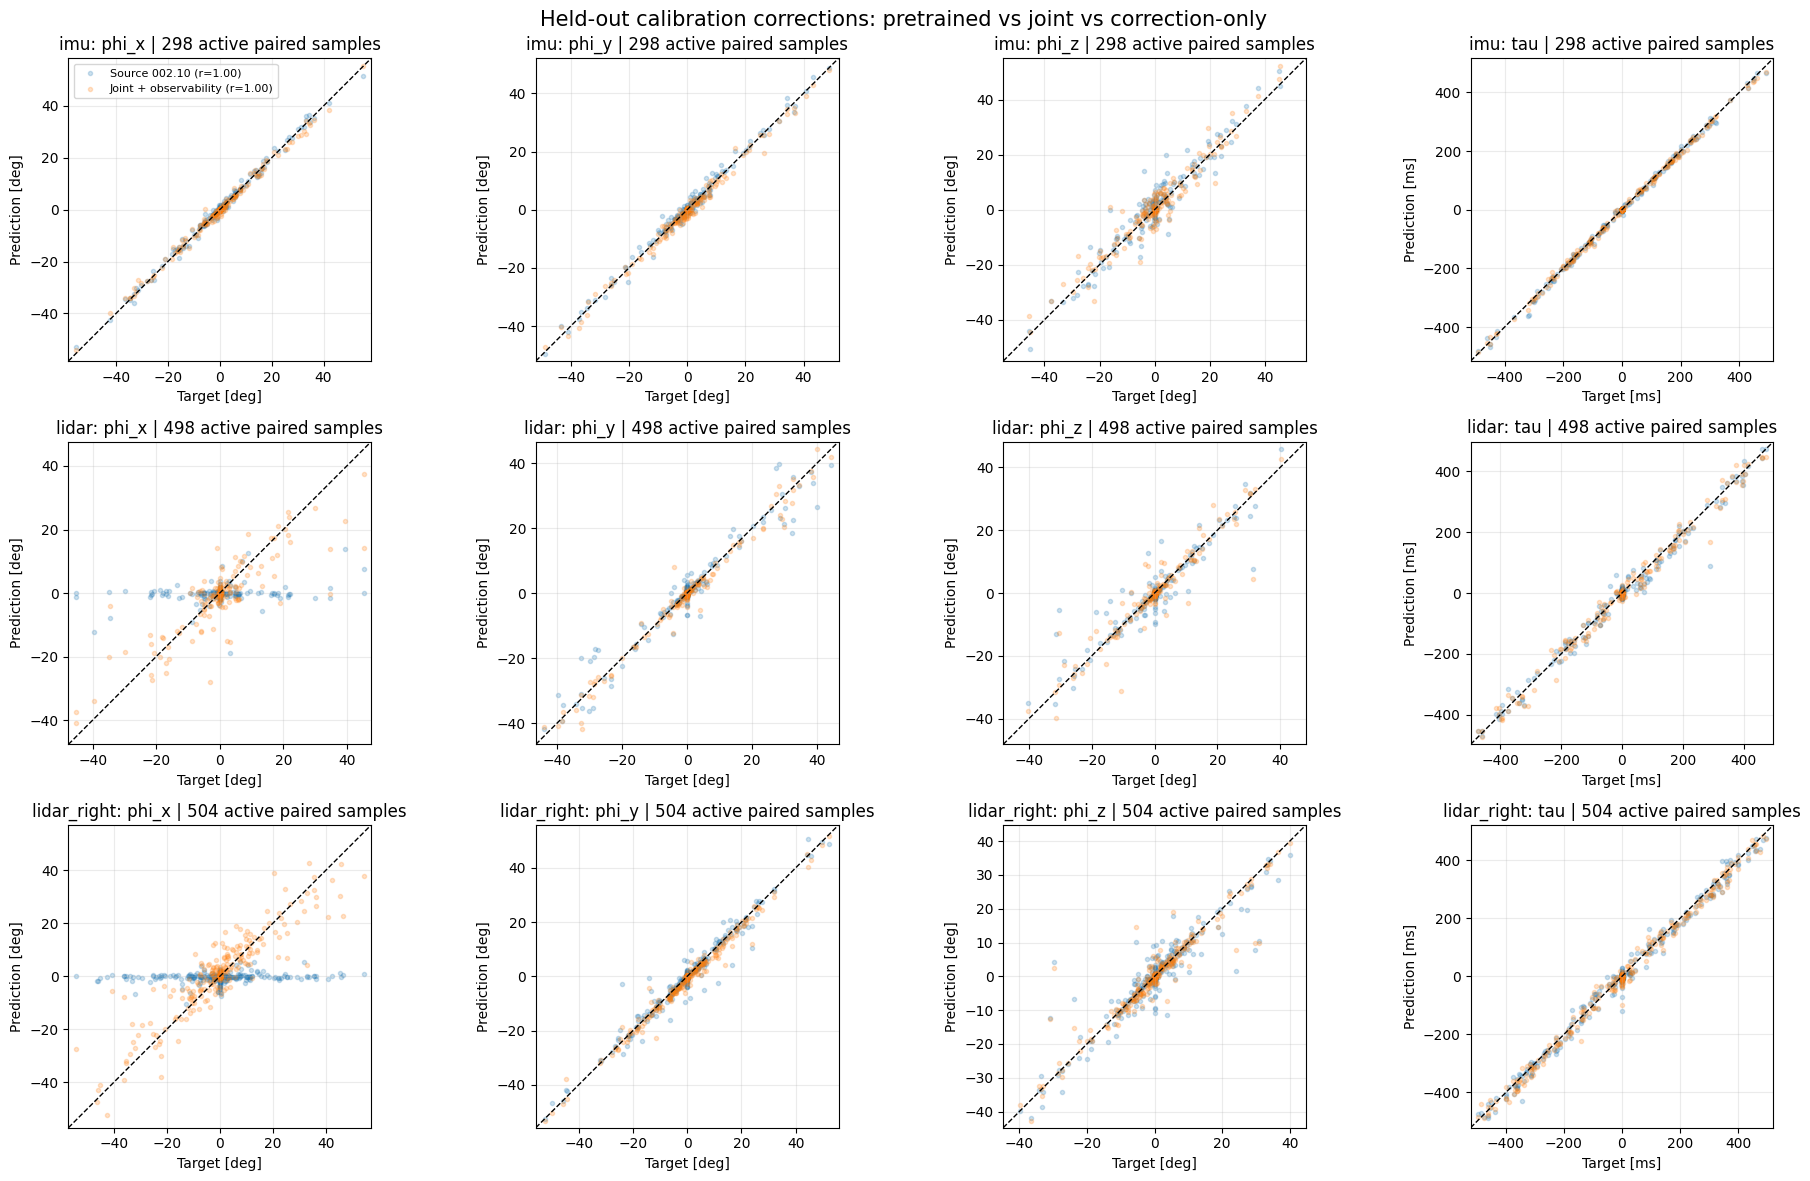

Matched active-sensor test MAE and Pearson correlation:

imu
  phi_x | Source 002.10: MAE=0.641 deg, r=0.997 | Joint + observability: MAE=0.584 deg, r=0.997
  phi_y | Source 002.10: MAE=0.790 deg, r=0.994 | Joint + observability: MAE=0.735 deg, r=0.994
  phi_z | Source 002.10: MAE=2.005 deg, r=0.955 | Joint + observability: MAE=1.723 deg, r=0.961
  tau | Source 002.10: MAE=4.193 ms, r=0.999 | Joint + observability: MAE=3.682 ms, r=0.999

lidar
  phi_x | Source 002.10: MAE=2.794 deg, r=0.274 | Joint + observability: MAE=1.511 deg, r=0.838
  phi_y | Source 002.10: MAE=0.945 deg, r=0.969 | Joint + observability: MAE=0.485 deg, r=0.988
  phi_z | Source 002.10: MAE=1.042 deg, r=0.925 | Joint + observability: MAE=0.743 deg, r=0.944
  tau | Source 002.10: MAE=8.653 ms, r=0.991 | Joint + observability: MAE=6.507 ms, r=0.993

lidar_right
  phi_x | Source 002.10: MAE=5.645 deg, r=0.162 | Joint + observability: MAE=2.398 deg, r=0.903
  phi_y | Source 002.10: MAE=0.981 deg, r=0.978 | Joint + obser

In [35]:

# Cell 1: Matched calibration correlations for source, jointly fine-tuned, and correction-only models.
# Run after the optional joint-training section in notebook 31.

CALIBRATION_SCATTER_NUM_WINDOWS = min(256, len(test_dataset))  # Set to len(test_dataset) for the entire test set.
CALIBRATION_SCATTER_BATCH_SIZE = 8
CALIBRATION_SCATTER_SEED = TEST_PAIR_SEED + 310050

if not JOINT_BEST_PATH.is_file():
    raise FileNotFoundError(f"Run Stage 3 first. Joint checkpoint not found: {JOINT_BEST_PATH}")

# Load the jointly fine-tuned model.
joint_model.to(device=DEVICE, dtype=MODEL_DTYPE)
load_training_checkpoint(JOINT_BEST_PATH, model=joint_model, map_location=DEVICE, restore_rng_state=False)

source_model.to(device=DEVICE, dtype=MODEL_DTYPE)

scatter_backbones = {
    "Source 002.10": source_model,
    "Joint + observability": joint_model.calibration_model,
}

# Include the correction-only control only when explicitly enabled.
EVALUATE_CONTROL = RUN_CONTROL

if EVALUATE_CONTROL:
    if not CONTROL_BEST_PATH.is_file():
        raise FileNotFoundError(f"Control checkpoint not found: {CONTROL_BEST_PATH}")

    control_model.to(device=DEVICE, dtype=MODEL_DTYPE)
    load_training_checkpoint(CONTROL_BEST_PATH, model=control_model, map_location=DEVICE, restore_rng_state=False)
    scatter_backbones["Correction-only"] = control_model

# Ensure all evaluated models are on the same device as the input tokens.
for name, backbone in scatter_backbones.items():
    backbone.eval()

    model_device = next(backbone.parameters()).device
    expected_device = torch.device(DEVICE)

    if model_device.type != expected_device.type or (expected_device.index is not None and model_device.index != expected_device.index):
        raise RuntimeError(f"{name} is on {model_device}, expected {expected_device}")

print("Evaluating:", list(scatter_backbones))

with torch.inference_mode():
    # Always create fresh lists before collecting predictions.
    scatter_chunks = {
        key: {"target": [], **{name: [] for name in scatter_backbones}}
        for key in CALIBRATION_KEYS
    }

    for start in range(0, len(scatter_indices), CALIBRATION_SCATTER_BATCH_SIZE):
        indices = scatter_indices[start:start + CALIBRATION_SCATTER_BATCH_SIZE]
        base_window = collate_windows([test_dataset[int(i)] for i in indices])
        base_window = window_batch_to(base_window, DEVICE, dtype=MODEL_DTYPE)
        positive_window, negative_window, _, _ = make_paired_windows(base_window, generator=scatter_generator)

        for window in (positive_window, negative_window):
            outputs = {name: calibration_forward(window, backbone=backbone) for name, backbone in scatter_backbones.items()}

            for key in CALIBRATION_KEYS:
                target_xi, target_tau = correction_target(window, key)
                active = (torch.linalg.vector_norm(target_xi[:, :3], dim=-1) > 1e-8) | (target_tau[:, 0].abs() > 1e-8)
                if not bool(active.any()):
                    continue

                target = torch.cat((torch.rad2deg(target_xi[:, :3]), 1000.0 * target_tau), dim=-1)
                scatter_chunks[key]["target"].append(target[active].cpu().numpy())

                for name, output in outputs.items():
                    prediction = output.predictions[key]
                    predicted = torch.cat((torch.rad2deg(prediction.delta_xi[:, :3]), 1000.0 * prediction.delta_tau), dim=-1)
                    scatter_chunks[key][name].append(predicted[active].cpu().numpy())

scatter_points = {}

for key in CALIBRATION_KEYS:
    scatter_points[key] = {}

    for name, chunks in scatter_chunks[key].items():
        if not chunks:
            raise ValueError(f"No samples collected for {key}, {name}")

        scatter_points[key][name] = np.concatenate(chunks, axis=0)

    expected_count = len(scatter_points[key]["target"])

    for name in scatter_backbones:
        assert len(scatter_points[key][name]) == expected_count, f"{key}: {name} count mismatch"

    print(f"{key}: {expected_count} active samples")


def _scatter_pearson(a, b):
    return float(np.corrcoef(a, b)[0, 1]) if len(a) > 1 and np.std(a) > 1e-10 and np.std(b) > 1e-10 else float("nan")


component_names = ("phi_x", "phi_y", "phi_z", "tau")
component_units = ("deg", "deg", "deg", "ms")
fig, axes = plt.subplots(len(CALIBRATION_KEYS), len(component_names), figsize=(19, 12), squeeze=False)

for row, key in enumerate(CALIBRATION_KEYS):
    target = scatter_points[key]["target"]
    for col, (component, unit) in enumerate(zip(component_names, component_units)):
        ax = axes[row, col]
        x = target[:, col]
        plotted_values = [x]

        for name in scatter_backbones:
            y = scatter_points[key][name][:, col]
            ax.scatter(x, y, s=9, alpha=0.22, label=f"{name} (r={_scatter_pearson(x, y):.2f})", rasterized=True)
            plotted_values.append(y)

        limit = max(1e-6, max(float(np.max(np.abs(a))) for a in plotted_values) * 1.05)
        ax.plot([-limit, limit], [-limit, limit], "k--", linewidth=1)
        ax.set_xlim(-limit, limit)
        ax.set_ylim(-limit, limit)
        ax.set_aspect("equal", adjustable="box")
        ax.set_title(f"{key}: {component} | {len(x)} active paired samples")
        ax.set_xlabel(f"Target [{unit}]")
        ax.set_ylabel(f"Prediction [{unit}]")
        ax.grid(True, alpha=0.25)
        if row == 0 and col == 0:
            ax.legend(fontsize=8, loc="best")

fig.suptitle("Held-out calibration corrections: pretrained vs joint vs correction-only", fontsize=15)
fig.tight_layout()
plt.show()

print("Matched active-sensor test MAE and Pearson correlation:")
for key in CALIBRATION_KEYS:
    print(f"\n{key}")
    for col, component in enumerate(component_names):
        target = scatter_points[key]["target"][:, col]
        print(" ", component, "|", " | ".join(
            f"{name}: MAE={np.mean(np.abs(scatter_points[key][name][:, col] - target)):.3f} {component_units[col]}, r={_scatter_pearson(target, scatter_points[key][name][:, col]):.3f}"
            for name in scatter_backbones
        ))


Mean test MSE | train-mean baseline: 0.026249
Mean test MSE | frozen probe:        0.022435
Mean test MSE | jointly trained:     0.004606


,sensor,dof,MSE_frozen,Pearson_frozen,R2_frozen,MSE_joint,Pearson_joint,R2_joint,target_std,train_mean_MSE
0,imu,phi_x,0.0473,0.0076,-0.2594,0.0048,0.9391,0.8710,0.1938,0.0436
1,imu,phi_y,0.0387,-0.0272,-0.0954,0.0075,0.8961,0.7879,0.1881,0.0377
2,imu,phi_z,0.0229,0.0744,-0.0364,0.0026,0.9440,0.8837,0.1488,0.0229
3,imu,rho_x,0.0001,NaN,NaN,0.0000,NaN,NaN,0.0000,0.0000
4,imu,rho_y,0.0000,NaN,NaN,0.0000,NaN,NaN,0.0000,0.0000
5,imu,rho_z,0.0000,NaN,NaN,0.0000,NaN,NaN,0.0000,0.0000
6,imu,tau,0.1024,0.1047,-0.2302,0.0081,0.9637,0.9021,0.2885,0.0946
7,lidar,phi_x,0.0293,0.4621,0.1413,0.0039,0.9467,0.8850,0.1848,0.0387
8,lidar,phi_y,0.0364,0.4512,0.1805,0.0099,0.8815,0.7762,0.2106,0.0451
9,lidar,phi_z,0.0304,0.4475,0.1697,0.0097,0.8631,0.7354,0.1914,0.0371


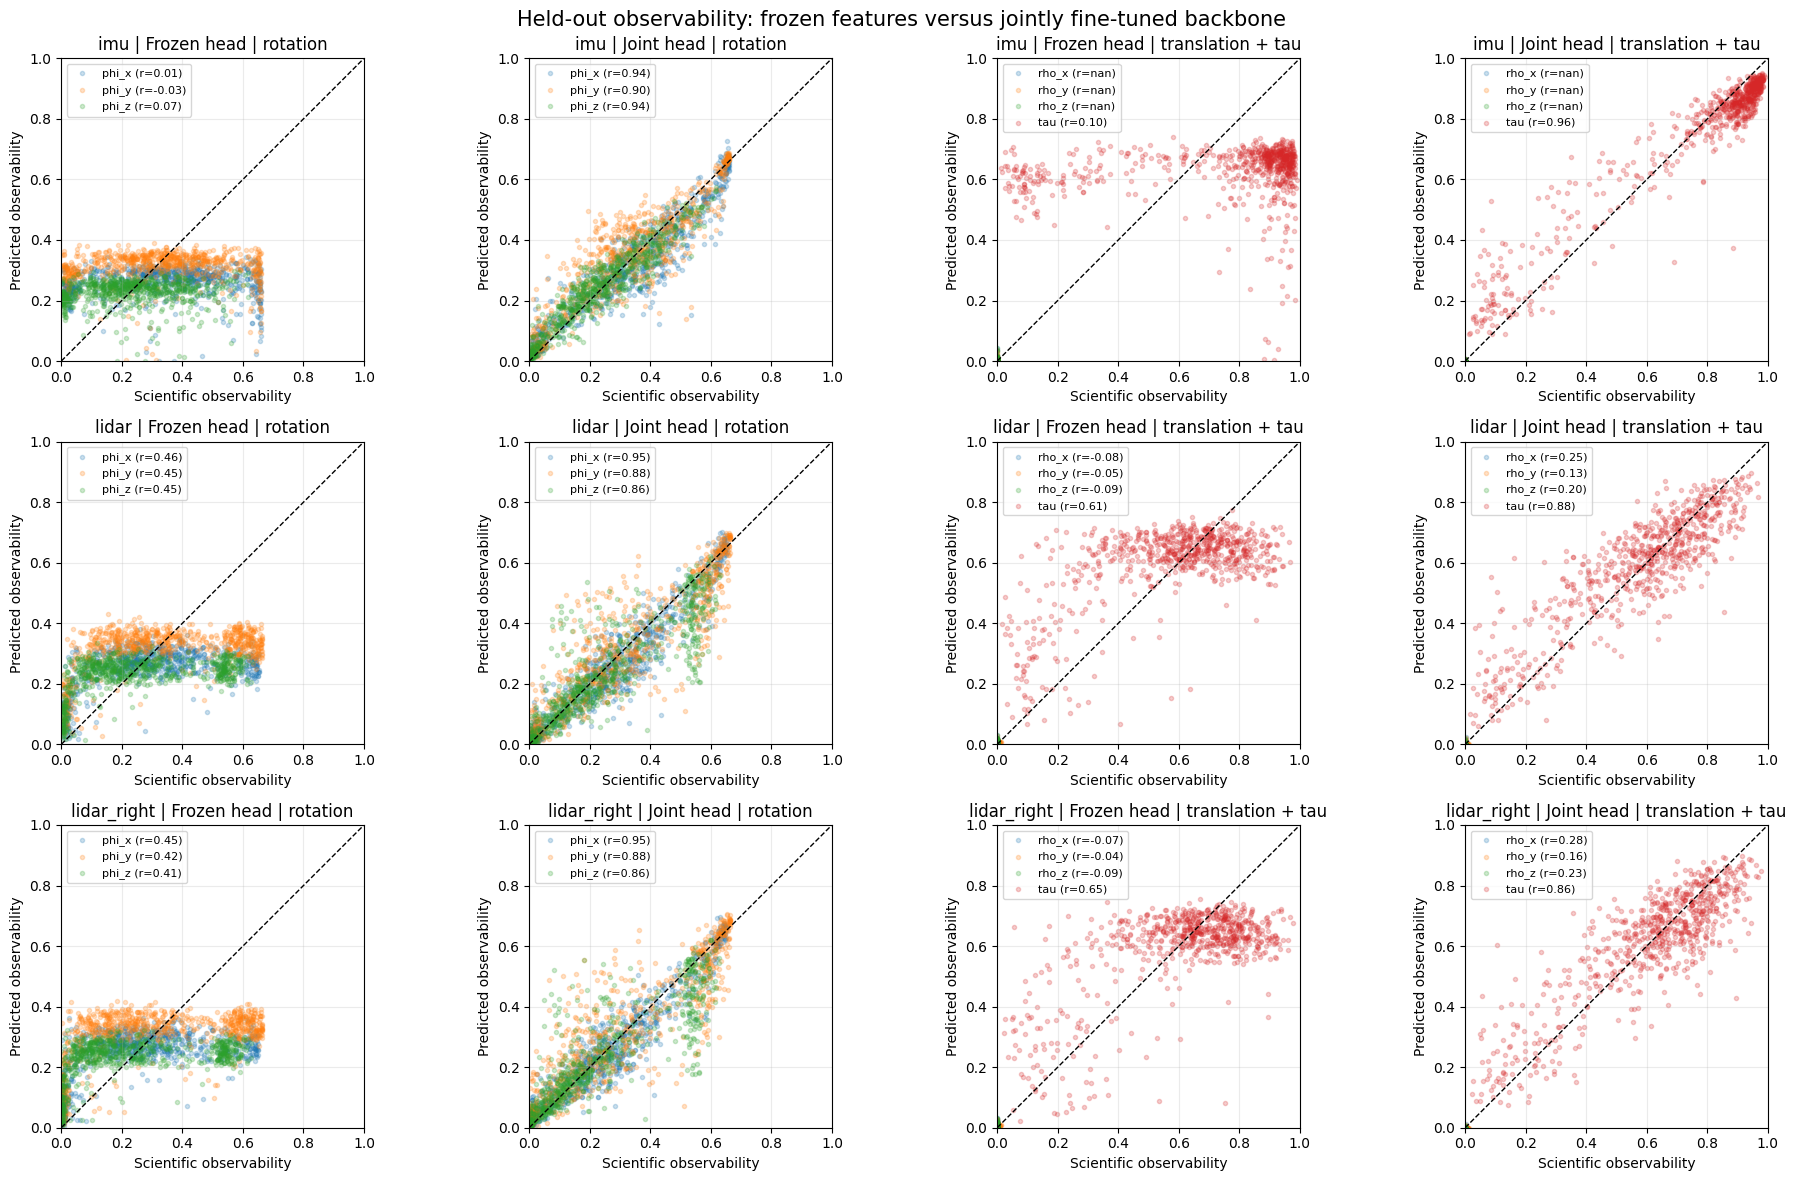

In [36]:

# Cell 2: Frozen observability probe versus jointly fine-tuned observability head.
# Predictions are computed from unaugmented physical windows, matching the FG-derived cache.

if not JOINT_BEST_PATH.is_file():
    raise FileNotFoundError(f"Run Stage 3 first. Joint checkpoint not found: {JOINT_BEST_PATH}")

load_training_checkpoint(JOINT_BEST_PATH, model=joint_model, map_location=DEVICE, restore_rng_state=False)
joint_model.eval()

joint_obs_pred = torch.empty_like(test_target_cache.values)
raw_test_loader = make_kaist_dataloader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, drop_last=False, num_workers=NUM_WORKERS)

with torch.inference_mode():
    for base_window in raw_test_loader:
        indices = torch.as_tensor(base_window.dataset_indices).cpu().long()
        window = window_batch_to(base_window, DEVICE, dtype=MODEL_DTYPE)
        features = forward_joint(window, joint_model).shared_features
        joint_obs_pred[indices] = joint_model.observability_head(features).cpu()

frozen_obs_pred = probe_predict(frozen_test_features)
scientific_obs = test_target_cache.values.float()
train_mean_obs = train_target_cache.values.float().mean(dim=0)

joint_obs_metrics = observability_metrics(joint_obs_pred, scientific_obs, train_mean_obs)
frozen_obs_metrics = observability_metrics(frozen_obs_pred, scientific_obs, train_mean_obs)
print("Mean test MSE | train-mean baseline:", f"{joint_obs_metrics['train_mean_MSE'].mean():.6f}")
print("Mean test MSE | frozen probe:       ", f"{frozen_obs_metrics['MSE'].mean():.6f}")
print("Mean test MSE | jointly trained:    ", f"{joint_obs_metrics['MSE'].mean():.6f}")

comparison = frozen_obs_metrics[["sensor", "dof", "MSE", "Pearson", "R2"]].merge(
    joint_obs_metrics[["sensor", "dof", "MSE", "Pearson", "R2", "target_std", "train_mean_MSE"]],
    on=["sensor", "dof"], suffixes=("_frozen", "_joint")
)
display(comparison.round(4))

fig, axes = plt.subplots(len(CALIBRATION_KEYS), 4, figsize=(19, 12), squeeze=False)
groups = ((0, 1, 2), (3, 4, 5, 6))

for sensor_id, key in enumerate(CALIBRATION_KEYS):
    for group_id, dofs in enumerate(groups):
        for model_id, (model_name, predictions) in enumerate((("Frozen head", frozen_obs_pred), ("Joint head", joint_obs_pred))):
            ax = axes[sensor_id, 2 * group_id + model_id]
            for dof_id in dofs:
                truth = scientific_obs[:, sensor_id, dof_id].numpy()
                predicted = predictions[:, sensor_id, dof_id].numpy()
                r = _scatter_pearson(truth, predicted)
                ax.scatter(truth, predicted, s=9, alpha=0.23, label=f"{OBSERVABILITY_PARAMETER_NAMES[dof_id]} (r={r:.2f})", rasterized=True)

            ax.plot([0, 1], [0, 1], "k--", linewidth=1)
            ax.set_xlim(0, 1)
            ax.set_ylim(0, 1)
            ax.set_aspect("equal", adjustable="box")
            ax.set_title(f"{key} | {model_name} | {'rotation' if group_id == 0 else 'translation + tau'}")
            ax.set_xlabel("Scientific observability")
            ax.set_ylabel("Predicted observability")
            ax.grid(True, alpha=0.25)
            ax.legend(fontsize=8, loc="best")

fig.suptitle("Held-out observability: frozen features versus jointly fine-tuned backbone", fontsize=15)
fig.tight_layout()
plt.show()


## 19. Interpretation

- **Frozen head beats train-mean baseline:** the pretrained calibration representation retains information predictive of the FG-derived observability score. This does *not* by itself establish that the correction output is observability-aware.
- **Frozen head ≈ constant baseline:** the head may only reproduce coordinate-specific average observability; avoid interpreting low overall MSE as learning meaningful window information.
- **Joint > correction-only on identical paired test cases:** auxiliary supervision adds value to calibration. A joint gain versus the frozen source *alone* is not enough, because either model benefits from additional fine-tuning.
- **Scores near zero and corrections near zero:** these need not mean the model has learned to recognize unobservability. They can result from symmetric target averaging under MSE.
- **Cached observability:** built on original windows using a scientific factor-graph estimator, not the separate observability NN. A deployment-ready model can generate its auxiliary score itself; it does *not* require cache or factor graph at inference once the head is trained.

No translation calibration or new geometric information is introduced in this experiment. Observability is a **learned auxiliary output**, not a signed calibration residual.

If joint training does **not** outperform the correction-only control on held-out calibration errors, keep the best correction-only checkpoint and treat the auxiliary output as a confidence/observability feature rather than a way to improve correction accuracy. No retraining from random weights is needed.
